# Git에 저장

In [1]:
# ===== 팀 프로젝트 시작 셀 =====
import os, sys
from google.colab import userdata

TOKEN = userdata.get('GITHUB_TOKEN')
NAME = "Hyunho"
REPO_URL = "github.com/DA15-Lab/team3-ping-analytics.git"
PROJECT_DIR = "/content/team3-ping-analytics"

if not os.path.exists(PROJECT_DIR):
    !git clone -q https://{TOKEN}@{REPO_URL}
    %cd {PROJECT_DIR}
else:
    %cd {PROJECT_DIR}
    !git pull -q

!git config user.email "{NAME}@example.com"
!git config user.name "{NAME}"

!pip install -q -r requirements.txt

sys.path.append("/content/team3-ping-analytics/src")
from preprocessing import *

print(module_test())
print("✅ 준비 완료")

/content/team3-ping-analytics
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 53.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.3/190.3 MB 4.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 341.3/341.3 kB 10.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 38.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 77.4 MB/s eta 0:00:00
✅ 모듈 설치 완료
✅ 준비 완료


In [ ]:
# ===== 작업 저장 셀 =====
NAME = "Hyunho"
PROJECT_DIR = "/content/team3-ping-analytics"

%cd {PROJECT_DIR}
!git config pull.rebase false
!git config core.editor "true"

!git pull
!pip install -q -r requirements.txt

from google.colab import _message
import json

with open(f'notebooks/{NAME}_analysis.ipynb', 'w') as f:
    json.dump(_message.blocking_request('get_ipynb', timeout_sec=30)['ipynb'], f)

!pip freeze | grep -v "google-colab" > requirements.txt

!git add .
!git commit -m "작업한 내용 메시지"
!git push

/content/team3-ping-analytics
Already up to date.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 90.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


# 데이터 불러오기

In [ ]:
import os

In [ ]:
# 한글 폰트 지원 패키지 설치
!pip install -q koreanize-matplotlib

# matplotlib 한글 폰트 적용
import koreanize_matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 53.3 MB/s eta 0:00:00


In [ ]:
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path = '/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/00_원본 csv/'

In [ ]:
users = pd.read_csv(path + 'accounts_user.csv')
groups = pd.read_csv(path + 'accounts_group.csv')
schools = pd.read_csv(path + 'accounts_school.csv')

In [ ]:
account_user = pd.read_csv(path + 'accounts_userquestionrecord.csv')

In [ ]:
attendance = pd.read_csv(path + 'accounts_attendance.csv')
friendrequest = pd.read_csv(path + 'accounts_friendrequest.csv')

qset = pd.read_csv(path + 'polls_questionset.csv')

In [ ]:
users.head()

,id,is_superuser,is_staff,gender,point,friend_id_list,is_push_on,created_at,block_user_id_list,hide_user_id_list,ban_status,report_count,alarm_count,pending_chat,pending_votes,group_id
0,831956,1,1,NaN,600,"[1292473, 913158, 1488461, 1064695, 1043565, 1...",0,2023-03-29 03:44:14.047130,[],[],N,0,0,0,0,NaN
1,831962,0,0,F,2248,"[833025, 832642, 982531, 879496, 838541, 83752...",1,2023-03-29 05:18:56.162368,[],[],N,253,40878,5499,110,12.0
2,832151,0,0,M,1519,"[838785, 982531, 882567, 879496, 838541, 83649...",0,2023-03-29 12:56:34.989468,[],[],N,0,37,0,47,1.0
3,832340,0,0,F,57,"[841345, 982531, 838785, 963714, 882567, 83252...",1,2023-03-29 12:56:35.020790,[],[],N,0,19,0,21,1.0
4,832520,0,0,M,1039,"[874050, 849763, 874212, 844297, 838541, 84004...",0,2023-03-29 12:56:35.049311,[],[],N,0,29,0,15,12.0


# 전처리

## account_user - opened_times 의미

In [ ]:
account_user.head()

,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
0,771777,C,2023-04-28 12:27:49,849469,252,849436,998458,0,N,2023-04-28 12:27:49,0,0
1,771800,C,2023-04-28 12:28:02,849446,244,849436,998459,0,N,2023-04-28 12:28:02,0,0
2,771812,C,2023-04-28 12:28:09,849454,183,849436,998460,1,N,2023-04-28 12:28:09,0,0
3,771828,C,2023-04-28 12:28:16,847375,101,849436,998461,0,N,2023-04-28 12:28:16,0,0
4,771851,C,2023-04-28 12:28:26,849477,209,849436,998462,1,N,2023-04-28 12:28:26,0,0


In [ ]:
# opened_times 기본 분포
print(account_user['opened_times'].value_counts().sort_index().head(20))

print('\n기초통계')
print(account_user['opened_times'].describe())

opened_times
0    1156896
1      46882
2      11120
3       2660
Name: count, dtype: int64

기초통계
count    1.217558e+06
mean     6.332511e-02
std      3.011468e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.000000e+00
Name: opened_times, dtype: float64


In [ ]:
# opened_times와 읽음 여부 관계
pd.crosstab(
    account_user['opened_times'],
    account_user['has_read'],
    margins=True
)

has_read,0,1,All
opened_times,,,
0,537995,618901,1156896
1,3632,43250,46882
2,0,11120,11120
3,0,2660,2660
All,541627,675931,1217558


In [ ]:
account_user.groupby(
    ['has_read', 'answer_status']
)['opened_times'].agg(
    count='count',
    mean='mean',
    median='median',
    max='max'
)

count      mean  median  max
has_read answer_status                               
0        N              541627  0.006706     0.0    1
1        A              111761  0.127021     0.0    3
         N              556305  0.103183     0.0    3
         P                7865  0.238144     0.0    3

In [ ]:
account_user['opened_times'].value_counts().sort_index()

,count
opened_times,
0,1156896
1,46882
2,11120
3,2660


In [ ]:
pd.crosstab(
    account_user['opened_times'],
    account_user['status'],
    margins=True
)

status,B,C,I,All
opened_times,,,,
0,574,1156322,0,1156896
1,56,0,46826,46882
2,20,0,11100,11120
3,8,0,2652,2660
All,658,1156322,60578,1217558


In [ ]:
account_user[(account_user['opened_times'] > 0) & (account_user['has_read'] == 0)][
    ['status', 'answer_status', 'opened_times', 'has_read']
].value_counts()

,,,,count
status,answer_status,opened_times,has_read,
I,N,1,0,3629
B,N,1,0,3


## User 테이블 전처리

In [ ]:
users = pd.read_csv(
    path + 'accounts_user.csv',
    usecols=[
        'id',
        'created_at',
        'group_id',
        'gender',
        'ban_status',
        'is_push_on',
        'pending_chat',
        'pending_votes'
    ]
)

In [ ]:
users.info()
users.isna().sum()
users.duplicated().sum()
users['id'].duplicated().sum()
users['group_id'].isna().sum()

users[['created_at']].describe()
users['ban_status'].value_counts(dropna=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 677085 entries, 0 to 677084
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   id             677085 non-null  int64  
 1   gender         677083 non-null  object 
 2   is_push_on     677085 non-null  int64  
 3   created_at     677085 non-null  object 
 4   ban_status     677085 non-null  object 
 5   pending_chat   677085 non-null  int64  
 6   pending_votes  677085 non-null  int64  
 7   group_id       677082 non-null  float64
dtypes: float64(1), int64(4), object(3)
memory usage: 41.3+ MB


,count
ban_status,
N,668432
W,7855
NB,608
RB,190


### 결측치 확인

In [ ]:
users[users.isna().any(axis=1)]

,id,gender,is_push_on,created_at,ban_status,pending_chat,pending_votes,group_id
0,831956,NaN,0,2023-03-29 03:44:14.047130,N,0,0,NaN
138959,995177,F,1,2023-05-08 07:25:51.737820,N,0,0,NaN
674052,1580689,NaN,0,2023-09-24 17:39:12.897884,N,0,0,NaN


결측치 삭제

In [ ]:
users = users.dropna(subset=['gender', 'group_id']).copy()

In [ ]:
users['group_id'].value_counts()

,count
group_id,
67097.0,80
6431.0,79
13705.0,73
53560.0,69
36957.0,61
...,...
84542.0,1
84541.0,1
84539.0,1


In [ ]:
# 정수형 변환
users['group_id'] = users['group_id'].astype(int)

In [ ]:
users.duplicated().sum()

np.int64(0)

중복값 X

### 이상치 확인

In [ ]:
users.describe()

,id,is_push_on,pending_chat,pending_votes,group_id
count,6.770820e+05,677082.000000,677082.000000,677082.000000,677082.000000
mean,1.212969e+06,0.843100,0.098470,84.630893,37022.980168
std,2.138964e+05,0.363706,11.087794,123.262832,21997.765398
min,8.319620e+05,0.000000,-1.000000,0.000000,1.000000
25%,1.028076e+06,1.000000,0.000000,2.000000,18488.000000
50%,1.211730e+06,1.000000,0.000000,29.000000,35614.000000
75%,1.397906e+06,1.000000,0.000000,122.000000,54534.000000
max,1.583733e+06,1.000000,5712.000000,3352.000000,84546.000000


- pending_chat, pending_votes 이상치로 보이는 max 값 확인

In [ ]:
# 분포·상위 분위수 확인
users[['pending_chat', 'pending_votes']].describe(
    percentiles=[.90, .95, .99, .995, .999]
)

,pending_chat,pending_votes
count,677082.000000,677082.000000
mean,0.098470,84.630893
std,11.087794,123.262832
min,-1.000000,0.000000
50%,0.000000,29.000000
90%,0.000000,249.000000
95%,1.000000,339.000000
99%,2.000000,544.000000
99.5%,2.000000,634.000000
99.9%,5.000000,852.000000


In [ ]:

users['pending_votes'].nlargest(10)

,pending_votes
173166,3352
356987,2744
385284,2561
286755,2232
194954,2005
54922,1972
217912,1935
201289,1821
333584,1768
273183,1705


In [ ]:
users[users['pending_chat'] < 0]

,id,gender,is_push_on,created_at,ban_status,pending_chat,pending_votes,group_id
271084,1138370,M,1,2023-05-11 13:53:19.948562,N,-1,0,33550
366683,1242506,F,1,2023-05-14 01:41:16.929982,N,-1,5,46935
489170,1377119,M,1,2023-05-18 22:59:08.940361,N,-1,7,50365
505326,1395096,M,1,2023-05-20 03:53:16.178307,N,-1,0,64465
523372,1415448,M,1,2023-05-21 01:53:06.441420,N,-1,1,70939


마이너스 값들 삭제 진행

In [ ]:
users = users[users['pending_chat'] >= 0].copy()

In [ ]:
users['pending_chat'].value_counts().sort_index().head(20)

,count
pending_chat,
0,642825
1,26984
2,4647
3,1347
4,534
5,263
6,139
7,80
8,47


In [ ]:
(users['pending_chat'] > 1000).sum()

np.int64(4)

pending_chat 컬럼은 천 건이 넘는 행에 한해서 1000건이 안되는 값들 중 제일 큰 값으로 대체를 진행하겠다

In [ ]:
# 1000 이하 값 중 최댓값
max_normal = users.loc[users['pending_chat'] <= 1000, 'pending_chat'].max()

# 1000 초과값을 max_normal로 대체
users.loc[users['pending_chat'] > 1000, 'pending_chat'] = max_normal

print('대체값:', max_normal)

대체값: 256


In [ ]:
users['pending_chat'].nlargest(10)

,pending_chat
1,256
50,256
693,256
644656,256
671688,256
106823,161
113075,116
146208,115
81066,98
463456,59


In [ ]:
# 분포·상위 분위수 확인
users['pending_votes'].describe(
    percentiles=[.90, .95, .99, .995, .999]
)

,pending_votes
count,677077.000000
mean,84.631498
std,123.263085
min,0.000000
50%,29.000000
90%,249.000000
95%,339.000000
99%,544.000000
99.5%,634.000000
99.9%,852.000000


In [ ]:
q99 = users['pending_votes'].quantile(0.99)

pending_votes_99 = users.loc[
    users['pending_votes'] <= q99,
    'pending_votes'
]

print('99% 기준값:', q99)
print('평균:', pending_votes_99.mean())
print('중앙값:', pending_votes_99.median())
print('최대값:', pending_votes_99.max())
print('포함 행 수:', len(pending_votes_99))

99% 기준값: 544.0
평균: 78.6372006844482
중앙값: 28.0
최대값: 544
포함 행 수: 670321


In [ ]:
# UQR 기준 유저별 받은 투표 수
received = (
    account_user.groupby('chosen_user_id')
    .size()
    .reset_index(name='received_votes')
)

# accounts_user의 pending_votes와 연결
check = users[['id', 'pending_votes']].merge(
    received,
    left_on='id',
    right_on='chosen_user_id',
    how='inner'
)

check[['received_votes', 'pending_votes']].describe()

,received_votes,pending_votes
count,15426.000000,15426.000000
mean,78.928951,105.775639
std,131.426705,134.760117
min,1.000000,0.000000
25%,3.000000,6.000000
50%,15.000000,55.000000
75%,97.000000,157.000000
max,1239.000000,1472.000000


pending_votes 의미 해석 및 전처리에 너무 많은 시간을 쏟기보다 팀원 모두 사용하지 않는 컬럼이라 추후 필요할때 다시 불러와서 전처리를 진행하도록 하겠다.

In [ ]:
users = users.drop(columns=['pending_votes'])

In [ ]:
users.columns

Index(['id', 'gender', 'is_push_on', 'created_at', 'ban_status',
       'pending_chat', 'group_id'],
      dtype='object')

In [ ]:
users.describe()

,id,is_push_on,pending_chat,group_id
count,6.770770e+05,677077.000000,677077.000000,677077.000000
mean,1.212969e+06,0.843099,0.074709,37022.860331
std,2.138968e+05,0.363708,0.896461,21997.773046
min,8.319620e+05,0.000000,0.000000,1.000000
25%,1.028075e+06,1.000000,0.000000,18488.000000
50%,1.211728e+06,1.000000,0.000000,35614.000000
75%,1.397906e+06,1.000000,0.000000,54534.000000
max,1.583733e+06,1.000000,256.000000,84546.000000


- alarm 컬럼 추가

In [ ]:
alarm = pd.read_csv(
    path + 'accounts_user.csv',
    usecols=['id', 'alarm_count']
)

users = users.merge(
    alarm,
    on='id',
    how='left',
    validate='one_to_one'
)

In [ ]:
users['alarm_count'].isna().sum()

np.int64(0)

In [ ]:
users['alarm_count'].describe()

,alarm_count
count,677077.000000
mean,0.946656
std,56.115190
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,40878.000000


In [ ]:
users['alarm_count'].value_counts().sort_index().head(20)

,count
alarm_count,
0,179631
1,439801
2,47225
3,6959
4,1705
5,632
6,340
7,175
8,137


In [ ]:
users['alarm_count'].describe(
    percentiles=[.90, .95, .99, .999]
)

,alarm_count
count,677077.000000
mean,0.946656
std,56.115190
min,0.000000
50%,1.000000
90%,1.000000
95%,2.000000
99%,3.000000
99.9%,7.000000
max,40878.000000


In [ ]:
users[users['alarm_count'] > 10][
    ['id', 'alarm_count', 'pending_chat', 'is_push_on', 'group_id']
].sort_values('alarm_count', ascending=False).head(20)

,id,alarm_count,pending_chat,is_push_on,group_id
0,831962,40878,256,1,12
692,838541,21442,256,1,9
49,834358,912,256,1,1
557283,1453061,238,0,1,61829
543372,1437875,201,3,1,1
408557,1288533,119,0,1,59045
644835,1549094,111,4,1,49564
604973,1505972,101,0,1,60786
54215,904023,71,0,1,16311
671634,1577899,69,1,1,61970


상위 3개 값들은 그 다음 값들에 비해 극단적으로 크기에 pending_chat에서 처럼 상한값 캠핑을 진행하겠다

In [ ]:
# 238 초과 alarm_count를 238로 대체
users.loc[users['alarm_count'] > 238, 'alarm_count'] = 238

In [ ]:
users['alarm_count'].describe()

,alarm_count
count,677077.000000
mean,0.854321
std,1.041887
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,238.000000


In [ ]:
# # 전처리 완료 테이블 저장
# users.to_csv('/content/accounts_user_cleaned.csv', index=False, encoding='utf-8-sig')

In [ ]:
# from google.colab import files

# files.download('/content/accounts_user_cleaned.csv')

## groups 테이블 전처리

In [ ]:
groups.info()
groups.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84515 entries, 0 to 84514
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         84515 non-null  int64
 1   grade      84515 non-null  int64
 2   class_num  84515 non-null  int64
 3   school_id  84515 non-null  int64
dtypes: int64(4)
memory usage: 2.6 MB


,id,grade,class_num,school_id
0,1,1,1,1
1,8,3,2,1
2,9,3,3,1
3,10,2,2,1
4,11,2,3,1


In [ ]:
groups.isna().sum()

,0
id,0
grade,0
class_num,0
school_id,0


In [ ]:
print('전체 중복 행:', groups.duplicated().sum())
print('id 중복:', groups['id'].duplicated().sum())

전체 중복 행: 0
id 중복: 0


In [ ]:
groups['grade'].value_counts(dropna=False).sort_index()

,count
grade,
1,19659
2,35581
3,29273
4,1
20,1


4학년과 20학년은 없기 때문에 확인 후 처리

In [ ]:
groups['class_num'].describe()

,class_num
count,84515.000000
mean,5.318606
std,4.089901
min,0.000000
25%,2.000000
50%,4.000000
75%,7.000000
max,41.000000


0, 41 값 확인 필요

In [ ]:
groups['school_id'].nunique()

5604

In [ ]:
# users.group_id가 실제 groups.id에 다 존재하는지 체크
print(
    'users의 group_id 중 group 테이블에 없는 값:',
    (~users['group_id'].isin(groups['id'])).sum()
)

users의 group_id 중 group 테이블에 없는 값: 0


### grade 이상치 처리

In [ ]:
# grade 4, 20 확인
grade_check = groups[~groups['grade'].isin([1, 2, 3])]

grade_check

,id,grade,class_num,school_id
32624,32644,4,10,4658
61622,61647,20,7,3867


In [ ]:
grade_check.merge(
    users.groupby('group_id').size().reset_index(name='user_count'),
    left_on='id',
    right_on='group_id',
    how='left'
)

,id,grade,class_num,school_id,group_id,user_count
0,32644,4,10,4658,NaN,NaN
1,61647,20,7,3867,NaN,NaN


해당 그룹은 비어있으므로 삭제 진행

In [ ]:
groups = groups[groups['grade'].isin([1, 2, 3])].copy()

In [ ]:
groups['grade'].value_counts().sort_index()

,count
grade,
1,19659
2,35581
3,29273


### class_num 이상치 처리

In [ ]:
# class_num = 41인 그룹
class41 = groups[groups['class_num'] == 41]

class41

,id,grade,class_num,school_id
70368,70394,1,41,736


In [ ]:
class_check = groups[groups['class_num'].isin([0, 41])]

class_check

,id,grade,class_num,school_id
62234,62259,2,0,4348
62626,62651,2,0,1820
70368,70394,1,41,736


In [ ]:
class_check = (
    groups[groups['class_num'].isin([0, 41])]
    .merge(
        users.groupby('group_id').size().reset_index(name='user_count'),
        left_on='id',
        right_on='group_id',
        how='left'
    )
    .merge(
        schools,
        left_on='school_id',
        right_on='id',
        how='left',
        suffixes=('_group', '_school')
    )
)

class_check

,id_group,grade,class_num,school_id,group_id,user_count,id_school,address,student_count,school_type
0,62259,2,0,4348,62259.0,1.0,4348,경상남도 김해시,151,M
1,62651,2,0,1820,62651.0,1.0,1820,충청남도 세종특별자치시,9,M
2,70394,1,41,736,NaN,NaN,736,전라북도 전주시 덕진구,292,H


In [ ]:
# class_num이 0 또는 41인 group 삭제
groups = groups[~groups['class_num'].isin([0, 41])].copy()

class_num인 경우 대응되는 유저 id가 한명씩 존재하므로 나중에 merge했을때 결측이 2건 생길 수 있다

merge 후 추후 추가 결측까지 삭제하도록 하겠다

In [ ]:
groups.describe()

,id,grade,class_num,school_id
count,84510.000000,84510.000000,84510.000000,84510.000000
mean,42278.450775,2.113774,5.318235,3079.496095
std,24401.181919,0.752369,4.088062,1675.043968
min,1.000000,1.000000,1.000000,1.000000
25%,21146.250000,2.000000,2.000000,1752.000000
50%,42277.500000,2.000000,4.000000,3023.000000
75%,63411.750000,3.000000,7.000000,4620.000000
max,84546.000000,3.000000,20.000000,5965.000000


In [ ]:
groups['class_num'].value_counts().sort_index(ascending=False)

,count
class_num,
20,2454
19,177
18,217
17,214
16,152
15,216
14,311
13,506
12,998


#### clasee_num 20반 확인

In [ ]:
# class_num=20의 학교 유형 / 학년 분포
groups[groups['class_num'] == 20]['grade'].value_counts().sort_index()

,count
grade,
1,291
2,1551
3,612


18·19·20반에 실제 유저가 얼마나 연결돼 있는지

In [ ]:
group_users = users.groupby('group_id').size().reset_index(name='user_count')

check_1820 = (
    groups[groups['class_num'].isin([18, 19, 20])]
    .merge(group_users, left_on='id', right_on='group_id', how='left')
)

check_1820['user_count'] = check_1820['user_count'].fillna(0)

check_1820.groupby('class_num')['user_count'].agg(
    group_count='count',
    groups_with_users=lambda x: (x > 0).sum(),
    avg_users='mean',
    median_users='median'
)

,group_count,groups_with_users,avg_users,median_users
class_num,,,,
18,217,173,1.368664,1.0
19,177,144,1.079096,1.0
20,2454,2015,2.479625,1.0


같은 학교·같은 학년에 1~19반과 20반이 같이 존재하는지

In [ ]:
school_grade_classes = (
    groups.groupby(['school_id', 'grade'])['class_num']
    .agg(list)
    .reset_index()
)

school_grade_classes['has_20'] = school_grade_classes['class_num'].apply(lambda x: 20 in x)
school_grade_classes['has_1_19'] = school_grade_classes['class_num'].apply(
    lambda x: any(1 <= n <= 19 for n in x)
)

pd.crosstab(
    school_grade_classes['has_20'],
    school_grade_classes['has_1_19']
)

has_1_19,False,True
has_20,,
False,0,11185
True,17,2436


In [ ]:
only20 = school_grade_classes[
    school_grade_classes['class_num'].apply(lambda x: set(x) == {20})
]

print('20반만 존재하는 학교-학년 수:', len(only20))
only20.head(20)

20반만 존재하는 학교-학년 수: 17


,school_id,grade,class_num,has_20,has_1_19
1152,508,3,[20],True,False
1366,602,2,[20],True,False
1502,671,2,[20],True,False
2914,1358,3,[20],True,False
3044,1419,3,[20],True,False
3608,1663,2,[20],True,False
4213,1910,3,[20],True,False
4908,2178,3,[20],True,False
6373,2769,1,[20],True,False
6578,2852,3,[20],True,False


In [ ]:
group_users = users.groupby('group_id').size().reset_index(name='user_count')

class20_check = (
    groups[groups['class_num'] == 20]
    .merge(
        group_users,
        left_on='id',
        right_on='group_id',
        how='left'
    )
)

# 연결 유저가 0명인 class_num=20
class20_zero = class20_check[class20_check['user_count'].isna()]

print('유저 0명인 20반 수:', len(class20_zero))
class20_zero.head(20)

유저 0명인 20반 수: 439


,id,grade,class_num,school_id,group_id,user_count
5,500,3,20,2045,NaN,NaN
6,872,2,20,2078,NaN,NaN
7,1176,1,20,2078,NaN,NaN
10,1594,2,20,2132,NaN,NaN
13,2458,2,20,2079,NaN,NaN
15,2654,2,20,2571,NaN,NaN
17,2767,3,20,1334,NaN,NaN
18,2966,3,20,2560,NaN,NaN
19,3023,3,20,2585,NaN,NaN
21,3159,1,20,4660,NaN,NaN


In [ ]:
# 유저 0명인 20반 삭제

groups = groups[~groups['id'].isin(class20_zero['id'])].copy()

print('삭제 후 20반 수:', (groups['class_num'] == 20).sum())

삭제 후 20반 수: 2015


In [ ]:
class20_users = (
    groups[groups['class_num'] == 20]
    .merge(
        users.groupby('group_id').size().reset_index(name='user_count'),
        left_on='id',
        right_on='group_id',
        how='left'
    )
)

class20_users['user_count'].describe()

,user_count
count,2015.000000
mean,3.019851
std,5.701060
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,80.000000


In [ ]:
class20_users['user_count'].value_counts().sort_index().head(20)

,count
user_count,
1,1226
2,304
3,121
4,84
5,55
6,35
7,25
8,25
9,18


유저 1명 연결된 20반: 1,226개

그다음 2명: 304개

3명: 121개

In [ ]:
class20_school_grade = groups[groups['class_num'] == 20][['school_id', 'grade']]

check = class20_school_grade.merge(
    groups,
    on=['school_id', 'grade'],
    how='left'
)

check.groupby(['school_id', 'grade'])['class_num'].agg(
    lambda x: sorted(x.unique())
).head(20)

school_id  grade
1          1            [1, 2, 3, 4, 5, 6, 7, 8, 9, 20]
           2                     [1, 2, 3, 4, 5, 7, 20]
           3            [1, 2, 3, 5, 7, 10, 16, 17, 20]
10         2                 [1, 2, 3, 4, 5, 6, 13, 20]
13         2                  [1, 2, 3, 4, 5, 6, 7, 20]
17         2          [1, 2, 3, 4, 5, 6, 7, 10, 12, 20]
18         3                  [1, 3, 4, 5, 6, 7, 8, 20]
19         2                                    [1, 20]
23         2                           [1, 2, 3, 4, 20]
39         2           [1, 2, 3, 4, 5, 6, 7, 8, 10, 20]
40         1        [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20]
           3                 [1, 2, 3, 6, 7, 8, 10, 20]
42         2                 [1, 2, 3, 4, 5, 6, 17, 20]
43         2           [1, 2, 3, 4, 5, 6, 7, 8, 17, 20]
46         1                   [1, 2, 3, 6, 10, 12, 20]
47         2                           [1, 2, 3, 4, 20]
           3                        [1, 2, 3, 4, 5, 20]
50         2                  [1, 2, 3, 4, 5, 6, 7, 20]
51         2              [2, 3, 4, 5, 6, 7, 8, 12, 20]
59         2                  [1, 2, 3, 4, 5, 6, 7, 20]
Name: class_num, dtype: object

In [ ]:
only20_check = (
    groups.groupby(['school_id', 'grade'])['class_num']
    .agg(lambda x: sorted(x.unique()))
    .reset_index(name='class_list')
)

only20_check['only_20'] = only20_check['class_list'].apply(
    lambda x: x == [20]
)

print('20반만 존재하는 학교-학년 수:', only20_check['only_20'].sum())

only20_check[only20_check['only_20']].head(20)

20반만 존재하는 학교-학년 수: 12


,school_id,grade,class_list,only_20
1365,602,2,[20],True
1501,671,2,[20],True
2913,1358,3,[20],True
3043,1419,3,[20],True
3607,1663,2,[20],True
4212,1910,3,[20],True
4907,2178,3,[20],True
6576,2852,3,[20],True
12151,5291,3,[20],True
12683,5504,1,[20],True


In [ ]:
has20 = only20_check[
    only20_check['class_list'].apply(lambda x: 20 in x)
]

print('20반 존재 학교-학년 수:', len(has20))
print('그중 20반만 존재:', has20['only_20'].sum())
print(
    '비율:',
    round(has20['only_20'].mean() * 100, 2),
    '%'
)

20반 존재 학교-학년 수: 2014
그중 20반만 존재: 12
비율: 0.6 %


20반 = 미지정/기타 코드일 가능성은 희박하다

In [ ]:
# 16~20반 group_id
target_group_ids = groups.loc[
    groups['class_num'].between(16, 20),
    'id'
]

# 16~20반 소속 유저
target_user_ids = set(
    users.loc[
        users['group_id'].isin(target_group_ids),
        'id'
    ]
)

# 투표 표본 유저
vote_user_ids = set(account_user['user_id'].dropna().unique())

# 겹치는 유저
matched_users = target_user_ids & vote_user_ids

print('16~20반 소속 유저 수:', len(target_user_ids))
print('투표 표본 유저 수:', len(vote_user_ids))
print('겹치는 유저 수:', len(matched_users))
print('16~20반 유저 중 투표자 비율:', round(len(matched_users) / len(target_user_ids) * 100, 2), '%')

16~20반 소속 유저 수: 7033
투표 표본 유저 수: 4849
겹치는 유저 수: 34
16~20반 유저 중 투표자 비율: 0.48 %


In [ ]:
# 17~20반 group_id
target_group_ids = groups.loc[
    groups['class_num'].between(17, 20),
    'id'
]

# 16~20반 소속 유저
target_user_ids = set(
    users.loc[
        users['group_id'].isin(target_group_ids),
        'id'
    ]
)

# 투표 표본 유저
vote_user_ids = set(account_user['user_id'].dropna().unique())

# 겹치는 유저
matched_users = target_user_ids & vote_user_ids

print('17~20반 소속 유저 수:', len(target_user_ids))
print('투표 표본 유저 수:', len(vote_user_ids))
print('겹치는 유저 수:', len(matched_users))
print('16~20반 유저 중 투표자 비율:', round(len(matched_users) / len(target_user_ids) * 100, 2), '%')

17~20반 소속 유저 수: 6825
투표 표본 유저 수: 4849
겹치는 유저 수: 33
16~20반 유저 중 투표자 비율: 0.48 %


In [ ]:
# 20반 group_id
class20_group_ids = groups.loc[
    groups['class_num'] == 20,
    'id'
]

# 20반 소속 유저
class20_user_ids = set(
    users.loc[
        users['group_id'].isin(class20_group_ids),
        'id'
    ]
)

# 투표 표본 유저
vote_user_ids = set(account_user['user_id'].dropna().unique())

# 겹치는 유저
matched_class20 = class20_user_ids & vote_user_ids

print('20반 소속 유저 수:', len(class20_user_ids))
print('20반 중 투표 표본과 겹치는 유저 수:', len(matched_class20))
print('20반 유저 중 투표자 비율:', round(len(matched_class20) / len(class20_user_ids) * 100, 2), '%')

20반 소속 유저 수: 6085
20반 중 투표 표본과 겹치는 유저 수: 33
20반 유저 중 투표자 비율: 0.54 %


In [ ]:
high_class_check = (
    groups[groups['class_num'].between(17, 19)][['school_id', 'grade']]
    .drop_duplicates()
    .merge(
        groups.groupby(['school_id', 'grade'])['class_num']
        .agg(lambda x: sorted(x.unique()))
        .reset_index(name='class_list'),
        on=['school_id', 'grade']
    )
)

high_class_check.head(30)

,school_id,grade,class_list
0,4494,3,"[1, 2, 3, 4, 5, 6, 7, 8, 19]"
1,2062,2,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 17]"
2,2078,1,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 17]"
3,1309,1,"[1, 2, 3, 4, 5, 17]"
4,2041,3,"[1, 2, 3, 4, 5, 17]"
5,2051,3,"[3, 4, 5, 6, 7, 8, 11, 12, 17]"
6,1403,1,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 18]"
7,300,2,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
8,271,1,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
9,1985,3,"[1, 2, 4, 5, 7, 8, 18]"


In [ ]:
def check_gap(class_list):
    high = [x for x in class_list if 17 <= x <= 19]
    low = [x for x in class_list if x <= 16]

    if not high or not low:
        return None

    return min(high) - max(low)

high_class_check['gap'] = high_class_check['class_list'].apply(check_gap)

high_class_check.sort_values('gap', ascending=False).head(30)

,school_id,grade,class_list,gap
272,1136,2,"[1, 19]",18.0
524,442,2,"[1, 2, 19, 20]",17.0
123,4754,2,"[1, 2, 19]",17.0
507,373,2,"[1, 18]",17.0
460,530,2,"[1, 2, 18, 20]",16.0
421,1385,2,"[1, 2, 18]",16.0
504,4739,2,"[1, 2, 3, 19]",16.0
388,4161,3,"[2, 18]",16.0
432,4279,2,"[1, 2, 3, 19]",16.0
377,5414,3,"[1, 2, 18]",16.0


In [ ]:
# class_num=20은 실제 학급 번호로 보기 어려운 패턴이 있어
# 원본값은 유지하되, 추후 학급 단위 분석에서는 제외

In [ ]:
groups.describe()

,id,grade,class_num,school_id
count,84071.000000,84071.000000,84071.000000,84071.000000
mean,42234.692010,2.113583,5.241570,3079.903439
std,24383.155305,0.752257,3.958289,1674.878741
min,1.000000,1.000000,1.000000,1.000000
25%,21127.500000,2.000000,2.000000,1752.000000
50%,42217.000000,2.000000,4.000000,3023.000000
75%,63341.500000,3.000000,7.000000,4620.000000
max,84546.000000,3.000000,20.000000,5965.000000


In [ ]:
# # 전처리 완료 후 파일 내보내기
# groups.to_csv('/content/accounts_group_cleaned.csv', index=False, encoding='utf-8-sig')

In [ ]:
# from google.colab import files
# #
# files.download('/content/accounts_group_cleaned.csv')

## accounts_school 전처리

In [ ]:
schools.head()

,id,address,student_count,school_type
0,4,충청북도 충주시,239,H
1,5,충청북도 충주시,160,M
2,6,충청북도 충주시,200,H
3,7,충청북도 충주시,114,H
4,8,충청북도 충주시,139,M


In [ ]:
schools.isna().sum()

,0
id,0
address,0
student_count,0
school_type,0


In [ ]:
schools.describe()

,id,student_count
count,5951.000000,5951.000000
mean,2981.026046,113.772979
std,1719.084020,102.863428
min,4.000000,0.000000
25%,1493.500000,16.000000
50%,2981.000000,97.000000
75%,4469.500000,183.000000
max,5965.000000,578.000000


In [ ]:
schools.duplicated().sum()

np.int64(0)

In [ ]:
schools['id'].duplicated().sum()

np.int64(0)

In [ ]:
# student_count = 0인 학교
print('student_count 0인 학교 수:', (schools['student_count'] == 0).sum())
schools[schools['student_count'] == 0]

student_count 0인 학교 수: 387


,id,address,student_count,school_type
17,21,충청북도 충주시,0,M
22,26,충청북도 충주시,0,H
31,35,충청북도 충주시,0,H
49,53,충청북도 청주시 흥덕구,0,H
92,96,충청북도 청주시 서원구,0,H
...,...,...,...,...
5902,5910,강원도 강릉시,0,M
5904,5912,강원도 강릉시,0,H
5929,5942,경북 의성군,0,H
5933,5947,경기도 성남시 분당구,0,H


In [ ]:
schools.groupby('school_type')['student_count'].describe()

,count,mean,std,min,25%,50%,75%,max
school_type,,,,,,,,
H,2661.0,141.349117,107.759162,0.0,51.0,130.0,217.0,578.0
M,3290.0,91.468997,92.937006,0.0,11.0,62.0,155.0,500.0


In [ ]:
# student_count = 0인 학교 id
zero_school_ids = set(
    schools.loc[schools['student_count'] == 0, 'id']
)

# 해당 학교에 연결된 group 수
zero_group_check = (
    groups[groups['school_id'].isin(zero_school_ids)]
    .groupby('school_id')
    .size()
    .reset_index(name='group_count')
)

print('0명 학교 중 group 존재 학교 수:', zero_group_check['school_id'].nunique())

0명 학교 중 group 존재 학교 수: 37


In [ ]:
user_school = (
    users[['id', 'group_id']]
    .merge(
        groups[['id', 'school_id']],
        left_on='group_id',
        right_on='id',
        how='left',
        suffixes=('_user', '_group')
    )
)

zero_user_check = (
    user_school[user_school['school_id'].isin(zero_school_ids)]
    .groupby('school_id')['id_user']
    .nunique()
    .reset_index(name='user_count')
)

print('0명 학교 중 실제 연결 유저가 있는 학교 수:',
      (zero_user_check['user_count'] > 0).sum())

0명 학교 중 실제 연결 유저가 있는 학교 수: 1


학생이 0명 존재하는 학교는 삭제하도록 하겠다

user와 연결했을때 1개의 학교는 실제 연결 유저가 있으니 유지하고 386개의 학교 정보 삭제 진행

In [ ]:
# 실제 연결 유저 수 계산
user_school = (
    users[['id', 'group_id']]
    .merge(
        groups[['id', 'school_id']],
        left_on='group_id',
        right_on='id',
        how='left',
        suffixes=('_user', '_group')
    )
)

school_user_count = (
    user_school.groupby('school_id')['id_user']
    .nunique()
    .reset_index(name='actual_user_count')
)

# schools에 실제 유저 수 붙이기
schools_check = schools.merge(
    school_user_count,
    left_on='id',
    right_on='school_id',
    how='left'
)

schools_check['actual_user_count'] = schools_check['actual_user_count'].fillna(0)

# student_count=0 이고 실제 유저도 0명인 학교만 삭제
delete_ids = schools_check.loc[
    (schools_check['student_count'] == 0) &
    (schools_check['actual_user_count'] == 0),
    'id'
]

schools = schools[~schools['id'].isin(delete_ids)].copy()

print('삭제 학교 수:', len(delete_ids))
print('남은 student_count=0 학교 수:', (schools['student_count'] == 0).sum())

삭제 학교 수: 386
남은 student_count=0 학교 수: 1


In [ ]:
# 삭제 후 확인
print('현재 학교 수:', len(schools))
print('student_count=0 학교 수:', (schools['student_count'] == 0).sum())

# 남아 있는 student_count=0 학교 확인
schools[schools['student_count'] == 0]

현재 학교 수: 5565
student_count=0 학교 수: 1


,id,address,student_count,school_type
4250,4257,경상남도 산청군,0,H


In [ ]:
schools.head()

,id,address,student_count,school_type
0,4,충청북도 충주시,239,H
1,5,충청북도 충주시,160,M
2,6,충청북도 충주시,200,H
3,7,충청북도 충주시,114,H
4,8,충청북도 충주시,139,M


In [ ]:
schools['address'].value_counts()

,count
address,
경기도 화성시,74
경기도 부천시,59
경기도 남양주시,57
경상남도 김해시,57
대구광역시 달서구,55
...,...
경기 군포시,1
경기 용인시 수지구,1
서울 동대문구,1


In [ ]:
# schools.to_csv('/content/accounts_school_cleaned.csv', index=False, encoding='utf-8-sig')

In [ ]:
# from google.colab import files

# files.download('/content/accounts_school_cleaned.csv')

## accounts_nearbyschool 전처리

In [ ]:
nearby = pd.read_csv(path + 'accounts_nearbyschool.csv')

In [ ]:
nearby.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59500 entries, 0 to 59499
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                59500 non-null  int64  
 1   distance          59500 non-null  float64
 2   nearby_school_id  59500 non-null  int64  
 3   school_id         59500 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 1.8 MB


In [ ]:
nearby.isna().sum()

,0
id,0
distance,0
nearby_school_id,0
school_id,0


In [ ]:
nearby.duplicated().sum()

np.int64(0)

In [ ]:
nearby.head()

,id,distance,nearby_school_id,school_id
0,119021,0.004564,6,7
1,119022,0.010787,13,7
2,119023,0.012928,20,7
3,119024,0.013590,4,7
4,119025,0.014122,24,7


In [ ]:
nearby.describe()

,id,distance,nearby_school_id,school_id
count,59500.000000,59500.000000,59500.000000,59500.000000
mean,148770.500000,0.055338,2976.695882,2980.524538
std,17176.314845,0.604024,1706.965231,1718.663078
min,119021.000000,0.000000,4.000000,4.000000
25%,133895.750000,0.011484,1518.000000,1493.000000
50%,148770.500000,0.021658,2973.000000,2980.500000
75%,163645.250000,0.064555,4448.000000,4469.000000
max,178520.000000,49.296594,5964.000000,5964.000000


In [ ]:
nearby_view = (
    nearby
    .merge(
        schools[['id', 'address']],
        left_on='school_id',
        right_on='id',
        how='left',
        suffixes=('', '_school')
    )
    .rename(columns={'address': 'school_address'})
    .drop(columns='id_school')
    .merge(
        schools[['id', 'address']],
        left_on='nearby_school_id',
        right_on='id',
        how='left',
        suffixes=('', '_nearby')
    )
    .rename(columns={'address': 'nearby_school_address'})
    .drop(columns='id_nearby')
)

nearby_view = nearby_view[
    ['school_id', 'school_address',
     'nearby_school_id', 'nearby_school_address',
     'distance']
]

In [ ]:
nearby_view.sort_values('distance', ascending=False).head(50)

,school_id,school_address,nearby_school_id,nearby_school_address,distance
59308,5948,-,615,제주특별자치도 서귀포시,49.296594
59307,5948,-,618,제주특별자치도 서귀포시,49.288493
59306,5948,-,553,제주특별자치도 제주시,49.224064
59305,5948,-,1155,NaN,49.222822
59304,5948,-,1026,전라남도 진도군,49.193698
59303,5948,-,1171,전라남도 신안군,49.149385
59302,5948,-,1420,인천광역시 옹진군,48.410895
59301,5948,-,1425,NaN,48.403180
59300,5948,-,5949,-,43.298250
59358,5949,-,570,제주특별자치도 제주시,6.254296


근처 학교 거리 정보가 결측이거나 뒤죽박죽인 5948, 5948 school_id 행은 삭제하도록 하겠다

In [ ]:
# school_id 5948, 5949 관련 행 제거
nearby = nearby[
    ~nearby['school_id'].isin([5948, 5949]) &
    ~nearby['nearby_school_id'].isin([5948, 5949])
].copy()

print(nearby.shape)

(59480, 4)


In [ ]:
nearby_view = (
    nearby
    .merge(
        schools[['id', 'address']],
        left_on='school_id',
        right_on='id',
        how='left',
        suffixes=('', '_school')
    )
    .rename(columns={'address': 'school_address'})
    .drop(columns='id_school')
    .merge(
        schools[['id', 'address']],
        left_on='nearby_school_id',
        right_on='id',
        how='left',
        suffixes=('', '_nearby')
    )
    .rename(columns={'address': 'nearby_school_address'})
    .drop(columns='id_nearby')
)

In [ ]:
# nearby_view에서 주소가 결측인 학교 ID
missing_school_ids = set(
    nearby_view.loc[
        nearby_view['school_address'].isna(),
        'school_id'
    ].unique()
)

missing_nearby_ids = set(
    nearby_view.loc[
        nearby_view['nearby_school_address'].isna(),
        'nearby_school_id'
    ].unique()
)

# accounts_school 전처리에서 삭제한 학교 ID
deleted_school_ids = set(delete_ids)

pd.DataFrame({
    '구분': ['기준 학교 결측', '주변 학교 결측'],
    '결측 ID 수': [len(missing_school_ids), len(missing_nearby_ids)],
    '삭제 학교와 일치 수': [
        len(missing_school_ids & deleted_school_ids),
        len(missing_nearby_ids & deleted_school_ids)
    ],
    '삭제 학교와 불일치 수': [
        len(missing_school_ids - deleted_school_ids),
        len(missing_nearby_ids - deleted_school_ids)
    ]
})

,구분,결측 ID 수,삭제 학교와 일치 수,삭제 학교와 불일치 수
0,기준 학교 결측,386,386,0
1,주변 학교 결측,386,386,0


nearbyschool에서 주소가 결측으로 나온 학교 ID 386개가

schools에서 삭제한 학교 ID 386개와 정확히 전부 일치

In [ ]:
nearby = nearby[
    ~nearby['school_id'].isin(delete_ids) &
    ~nearby['nearby_school_id'].isin(delete_ids)
].copy()

In [ ]:
nearby[
    nearby['school_id'].isin(delete_ids) |
    nearby['nearby_school_id'].isin(delete_ids)
]

,id,distance,nearby_school_id,school_id


In [ ]:
nearby.head()

,id,distance,nearby_school_id,school_id
0,119021,0.004564,6,7
1,119022,0.010787,13,7
2,119023,0.012928,20,7
3,119024,0.013590,4,7
4,119025,0.014122,24,7


In [ ]:
nearby.describe()

,id,distance,nearby_school_id,school_id
count,52879.000000,52879.000000,52879.000000,52879.000000
mean,148784.299627,0.042175,2979.140699,2981.861003
std,17035.911285,0.064215,1692.751912,1704.586971
min,119021.000000,0.000000,4.000000,4.000000
25%,134316.500000,0.010914,1564.000000,1535.000000
50%,148557.000000,0.020334,2956.000000,2959.000000
75%,163818.500000,0.052217,4472.000000,4486.000000
max,178520.000000,1.807119,5964.000000,5964.000000


In [ ]:
nearby['id'].duplicated().sum()

np.int64(0)

In [ ]:
nearby.duplicated(
    subset=['school_id', 'nearby_school_id']
).sum()

np.int64(0)

### distance = 0.0 인 행들 확인

In [ ]:
nearby[
    nearby['school_id'] == nearby['nearby_school_id']
]

,id,distance,nearby_school_id,school_id
9,119030,0.0,7,7
19,119040,0.0,8,8
29,119050,0.0,22,22
39,119060,0.0,13,13
49,119070,0.0,20,20
...,...,...,...,...
59459,178480,0.0,5959,5959
59469,178490,0.0,5960,5960
59479,178500,0.0,5964,5964
59489,178510,0.0,5963,5963


In [ ]:
nearby[nearby['distance'] == 0]

,id,distance,nearby_school_id,school_id
9,119030,0.0,7,7
19,119040,0.0,8,8
29,119050,0.0,22,22
39,119060,0.0,13,13
49,119070,0.0,20,20
...,...,...,...,...
59459,178480,0.0,5959,5959
59469,178490,0.0,5960,5960
59479,178500,0.0,5964,5964
59489,178510,0.0,5963,5963


In [ ]:
# distance = 0이고 school_id == nearby_school_id 인 경우 삭제
nearby = nearby[
    nearby['school_id'] != nearby['nearby_school_id']
].copy()

In [ ]:
nearby[
    nearby['school_id'] == nearby['nearby_school_id']
]

,id,distance,nearby_school_id,school_id


In [ ]:
nearby[
    (nearby['distance'] == 0) &
    (nearby['school_id'] != nearby['nearby_school_id'])
]

,id,distance,nearby_school_id,school_id
220,119241,0.0,28,27
230,119251,0.0,27,28
3170,122191,0.0,324,323
3200,122221,0.0,323,324
3220,122241,0.0,329,328
...,...,...,...,...
55460,174481,0.0,5553,5552
55950,174971,0.0,5619,5598
56120,175141,0.0,5598,5619
57040,176061,0.0,5720,5713


거리가 0이면서 주변 학교 아이디가 다른 경우 중-고등학교가 붙어있는건지 확인하기 위해 school_type과 연결

In [ ]:
zero_distance = nearby[
    (nearby['distance'] == 0) &
    (nearby['school_id'] != nearby['nearby_school_id'])
].copy()

school_info = schools[['id', 'school_type', 'address']].rename(
    columns={
        'id': 'school_id',
        'school_type': 'school_type',
        'address': 'school_address'
    }
)

nearby_school_info = schools[['id', 'school_type', 'address']].rename(
    columns={
        'id': 'nearby_school_id',
        'school_type': 'nearby_school_type',
        'address': 'nearby_school_address'
    }
)

zero_distance_check = (
    zero_distance
    .merge(school_info, on='school_id', how='left')
    .merge(nearby_school_info, on='nearby_school_id', how='left')
)

zero_distance_check[
    ['school_id', 'school_type', 'school_address',
     'nearby_school_id', 'nearby_school_type',
     'nearby_school_address', 'distance']
].head(30)

,school_id,school_type,school_address,nearby_school_id,nearby_school_type,nearby_school_address,distance
0,27,H,충청북도 충주시,28,H,충청북도 충주시,0.0
1,28,H,충청북도 충주시,27,H,충청북도 충주시,0.0
2,323,H,충청남도 천안시 동남구,324,H,충청남도 천안시 동남구,0.0
3,324,H,충청남도 천안시 동남구,323,H,충청남도 천안시 동남구,0.0
4,328,H,충청남도 예산군,329,H,충청남도 예산군,0.0
5,329,H,충청남도 예산군,328,H,충청남도 예산군,0.0
6,797,H,전라북도 익산시,798,H,전라북도 익산시,0.0
7,798,H,전라북도 익산시,797,H,전라북도 익산시,0.0
8,806,H,전라북도 익산시,807,H,전라북도 익산시,0.0
9,807,H,전라북도 익산시,806,H,전라북도 익산시,0.0


In [ ]:
zero_distance_check.groupby(
    ['school_type', 'nearby_school_type']
).size()

,,0
school_type,nearby_school_type,
H,H,122
M,M,126


distance=0인 서로 다른 학교 248건 중 중학교↔고등학교 조합은 0건

In [ ]:
# distance=0인 서로 다른 학교들의 주소 정보만 선택
zero_distance_check[
    ['school_id', 'school_type', 'school_address',
     'nearby_school_id', 'nearby_school_type', 'nearby_school_address']
]

# 기준 학교 주소와 nearby 학교 주소가 같은지 여부를 same_address 컬럼으로 생성
zero_distance_check[
    ['school_id', 'school_type', 'school_address',
     'nearby_school_id', 'nearby_school_type', 'nearby_school_address']
].assign(
    same_address=lambda x: x['school_address'] == x['nearby_school_address']
)

# 같은 주소(True) / 다른 주소(False)가 각각 몇 건인지 집계
zero_distance_check[
    ['school_id', 'school_type', 'school_address',
     'nearby_school_id', 'nearby_school_type', 'nearby_school_address']
].assign(
    same_address=lambda x: x['school_address'] == x['nearby_school_address']
)['same_address'].value_counts()

,count
same_address,
True,246
False,2


 False의 의미 : 학교 주소는 다른데 distance=0으로 저장된 경우

In [ ]:
# distance=0인데 주소 지역이 서로 다른 2건 확인
zero_distance_check[
    zero_distance_check['school_address']
    != zero_distance_check['nearby_school_address']
][
    ['school_id', 'school_type', 'school_address',
     'nearby_school_id', 'nearby_school_type',
     'nearby_school_address', 'distance']
]

,school_id,school_type,school_address,nearby_school_id,nearby_school_type,nearby_school_address,distance
224,5294,H,경기도 부천시,5302,H,경기도 부천시 소사구,0.0
225,5302,H,경기도 부천시 소사구,5294,H,경기도 부천시,0.0


In [ ]:
nearby[
    nearby.duplicated(
        subset=['school_id', 'nearby_school_id'],
        keep=False
    )
].sort_values(['school_id', 'nearby_school_id'])

,id,distance,nearby_school_id,school_id


In [ ]:
reverse = nearby.rename(columns={
    'school_id': 'nearby_school_id',
    'nearby_school_id': 'school_id',
    'distance': 'reverse_distance'
})[['school_id', 'nearby_school_id', 'reverse_distance']]

distance_check = nearby.merge(
    reverse,
    on=['school_id', 'nearby_school_id'],
    how='inner'
)

distance_check[
    (distance_check['distance'] - distance_check['reverse_distance']).abs() > 1e-6
][
    ['school_id', 'nearby_school_id', 'distance', 'reverse_distance']
]

,school_id,nearby_school_id,distance,reverse_distance


In [ ]:
# 삭제한 무가입 학교가 남아있는지
nearby[
    nearby['school_id'].isin(delete_ids) |
    nearby['nearby_school_id'].isin(delete_ids)
]

,id,distance,nearby_school_id,school_id


In [ ]:
# # 전처리 완료 nearbyschool 저장
# nearby.to_csv(
#     '/content/accounts_nearbyschool_cleaned.csv',
#     index=False,
#     encoding='utf-8-sig'
# )

In [ ]:
# from google.colab import files

# files.download('/content/accounts_nearbyschool_cleaned.csv')

# EDA

**학교 내 네트워크 규모와 신규 유저 초기 활성화의 관계**

유저-학교 기준 베이스 테이블
베이스 테이블 생성

- accounts_user + accounts_group + accounts_school merge
- 유저별 school_id, created_at 확보
- 학교별 가입순번 join_order 생성
- 학교별 40번째 가입일 생성

user_id | school_id | created_at | join_order | 40th_signup_date

In [ ]:
from pathlib import Path

In [ ]:
path = Path('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/01_전처리 완료된 csv')

In [ ]:
users = pd.read_csv(path / 'accounts_user_cleaned.csv')
groups = pd.read_csv(path / 'accounts_group_cleaned.csv')
schools = pd.read_csv(path / 'accounts_school_cleaned.csv')

users['created_at'] = pd.to_datetime(users['created_at'])

In [ ]:
# 유저 + 학급
base = users.merge(
    groups[['id', 'school_id', 'grade', 'class_num']],
    left_on='group_id',
    right_on='id',
    how='left',
    validate='many_to_one',
    suffixes=('_user', '_group')
)

# 학교 정보 추가
base = base.merge(
    schools[['id', 'student_count', 'school_type', 'address']],
    left_on='school_id',
    right_on='id',
    how='left',
    validate='many_to_one'
)

base = base.rename(columns={
    'id_user': 'user_id',
    'address': 'school_address'
})

base.head(10)

,user_id,gender,is_push_on,created_at,ban_status,pending_chat,group_id,alarm_count,id_group,school_id,grade,class_num,id,student_count,school_type,school_address
0,831962,F,1,2023-03-29 05:18:56.162368,N,256,12,238,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN
1,832151,M,0,2023-03-29 12:56:34.989468,N,0,1,37,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN
2,832340,F,1,2023-03-29 12:56:35.020790,N,0,1,19,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN
3,832520,M,0,2023-03-29 12:56:35.049311,N,0,12,29,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN
4,832614,M,1,2023-03-29 12:56:35.064406,N,0,12,28,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN
5,832740,M,0,2023-03-29 13:20:46.429584,NB,0,12,26,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN
6,832857,M,1,2023-03-29 13:20:46.460241,N,0,12,28,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN
7,832894,M,1,2023-03-29 13:20:46.469788,N,0,1,36,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN
8,832920,F,1,2023-03-29 13:20:46.476550,N,0,1,35,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN
9,832986,M,1,2023-03-29 13:20:46.493876,N,0,12,26,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN


In [ ]:
base.shape

(677077, 16)

In [ ]:
# merge로 생긴 PK 컬럼명을 명확하게 변경
base = base.rename(columns={ 'id_group': 'group_pk', 'id': 'school_pk' })

In [ ]:
base.head(1)

,user_id,gender,is_push_on,created_at,ban_status,pending_chat,group_id,alarm_count,group_pk,school_id,grade,class_num,school_pk,student_count,school_type,school_address
0,831962,F,1,2023-03-29 05:18:56.162368,N,256,12,238,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN


In [ ]:
# merge 검증용 컬럼 제거
base = base.drop(columns=['group_pk', 'school_pk'])

In [ ]:
base.head(1)

,user_id,gender,is_push_on,created_at,ban_status,pending_chat,group_id,alarm_count,school_id,grade,class_num,student_count,school_type,school_address
0,831962,F,1,2023-03-29 05:18:56.162368,N,256,12,238,1.0,2.0,1.0,NaN,NaN,NaN


In [ ]:
# 결측값 확인
base.isna().sum()

,0
user_id,0
gender,0
is_push_on,0
created_at,0
ban_status,0
pending_chat,0
group_id,0
alarm_count,0
school_id,2
grade,2


In [ ]:
base.duplicated().sum()

np.int64(0)

In [ ]:
check = pd.Series({
    '전체 유저': base['user_id'].nunique(),
    'school_id 없음': base.loc[base['school_id'].isna(), 'user_id'].nunique(),
    'school_id 있음 + 학교정보 없음': base.loc[
        base['school_id'].notna() & base['student_count'].isna(),
        'user_id'
    ].nunique()
})

check

,0
전체 유저,677077
school_id 없음,2
school_id 있음 + 학교정보 없음,95


In [ ]:
pd.Series({
    'users 행 수': len(users),
    'users 고유 id': users['id'].nunique(),
    'users id 결측': users['id'].isna().sum(),
    'users id 중복': users['id'].duplicated().sum(),
    'base 행 수': len(base),
    'base 고유 user_id': base['user_id'].nunique()
})

,0
users 행 수,677077
users 고유 id,677077
users id 결측,0
users id 중복,0
base 행 수,677077
base 고유 user_id,677077


조인 과정에서 유저 수가 줄어든 것은 아니고, 테이블 전처리 과정에서

677,085 -> 677,077 로 8명이 사라진 것으로 보인다

일단 불러온 base 테이블에서는 결측을 유지하고 네트워크 EDA를 위한 데이터프레임을 따로 만들어서 삭제 후 분석을 진행하도록 하겠다

## network_base 데이터프레임 생성

In [ ]:
# 학교 정보까지 정상 매칭된 네트워크 분석용 데이터
network_base = base.dropna(
    subset=['school_id', 'student_count', 'school_type', 'school_address']
).copy()

pd.Series({
    'base 유저 수': base['user_id'].nunique(),
    'network_base 유저 수': network_base['user_id'].nunique(),
    '제외 유저 수': base['user_id'].nunique() - network_base['user_id'].nunique()
})

,0
base 유저 수,677077
network_base 유저 수,676980
제외 유저 수,97


In [ ]:
network_base.isna().sum()

,0
user_id,0
gender,0
is_push_on,0
created_at,0
ban_status,0
pending_chat,0
group_id,0
alarm_count,0
school_id,0
grade,0


In [ ]:
# 가입일 datetime 변환
network_base['created_at'] = pd.to_datetime(network_base['created_at'])

# 학교별 가입 순서 계산
network_base = network_base.sort_values(['school_id', 'created_at', 'user_id']).copy()
network_base['join_order'] = network_base.groupby('school_id').cumcount() + 1

# 가입 순서 구간화
network_base['join_order_group'] = pd.cut(
    network_base['join_order'],
    bins=[0, 10, 20, 39, float('inf')],
    labels=['1~10번째', '11~20번째', '21~39번째', '40번째 이후']
)

network_base[['user_id', 'school_id', 'created_at', 'join_order', 'join_order_group']].head()

,user_id,school_id,created_at,join_order,join_order_group
148922,1005961,4.0,2023-05-08 11:36:21.504116,1,1~10번째
218976,1081808,4.0,2023-05-10 07:59:11.082388,2,1~10번째
226778,1090292,4.0,2023-05-10 11:40:57.616770,3,1~10번째
227237,1090778,4.0,2023-05-10 11:53:00.563227,4,1~10번째
227311,1090858,4.0,2023-05-10 11:54:28.888525,5,1~10번째


In [ ]:
network_base['join_order_group'].value_counts().sort_index()

,count
join_order_group,
1~10번째,50847
11~20번째,45220
21~39번째,77455
40번째 이후,503458


40이라는 서비스 임계값은 고정하고, 40 이후는 데이터 분포로 자르는 방식

처음에는 1-20 , 21-39, 40-100, 101 이후를 생각했으나 "왜 100이죠?" 라는 질문에 답할 수 없어서 위의 방식으로 진행하겠다

In [ ]:
# 40번째 이후 가입자들의 가입 순서 분포
post40 = network_base.loc[network_base['join_order'] >= 40, 'join_order']

post40.describe(percentiles=[0.25, 0.5, 0.75, 0.9])

,join_order
count,503458.000000
mean,133.234635
std,75.200472
min,40.000000
25%,74.000000
50%,116.000000
75%,175.000000
90%,239.000000
max,578.000000


In [ ]:
# 가입 순서 구간화
network_base['join_order_group'] = pd.cut(
    network_base['join_order'],
    bins=[0, 20, 39, 116, float('inf')],
    labels=['1~20번째', '21~39번째', '40~116번째', '117번째 이후']
)

network_base['join_order_group'].value_counts().sort_index()

,count
join_order_group,
1~20번째,96067
21~39번째,77455
40~116번째,254264
117번째 이후,249194


In [ ]:
# 학교별 실제 가입 유저 수
network_base['school_user_count'] = (
    network_base.groupby('school_id')['user_id'].transform('nunique')
)

# 학교별 최초 가입 시점
network_base['first_signup'] = (
    network_base.groupby('school_id')['created_at'].transform('min')
)

# 학교가 최종적으로 40명 이상 가입했는지 여부
network_base['reached_40'] = network_base['school_user_count'] >= 40

In [ ]:
# 학교별 40번째 가입자의 가입 시점
reached_40_map = (
    network_base[network_base['join_order'] == 40]
    .set_index('school_id')['created_at']
)

network_base['reached_40_at'] = (
    network_base['school_id'].map(reached_40_map)
)

In [ ]:
# 최초 가입자 발생 후 40명 달성까지 걸린 일수
network_base['days_to_40'] = (
    network_base['reached_40_at'] - network_base['first_signup']
).dt.days

network_base[
    ['user_id', 'school_id', 'join_order', 'join_order_group',
     'school_user_count', 'reached_40', 'reached_40_at', 'days_to_40']
].head()

,user_id,school_id,join_order,join_order_group,school_user_count,reached_40,reached_40_at,days_to_40
148922,1005961,4.0,1,1~20번째,235,True,2023-05-12 14:38:35.455537,4.0
218976,1081808,4.0,2,1~20번째,235,True,2023-05-12 14:38:35.455537,4.0
226778,1090292,4.0,3,1~20번째,235,True,2023-05-12 14:38:35.455537,4.0
227237,1090778,4.0,4,1~20번째,235,True,2023-05-12 14:38:35.455537,4.0
227311,1090858,4.0,5,1~20번째,235,True,2023-05-12 14:38:35.455537,4.0


In [ ]:
# 학교 단위 40명 달성 현황 확인
network_base[
    ['school_id', 'school_user_count', 'reached_40', 'days_to_40']
].drop_duplicates('school_id')['reached_40'].value_counts()

,count
reached_40,
True,3896
False,1654


In [ ]:
# 40명 달성 여부 비율(%)
network_base[
    ['school_id', 'reached_40']
].drop_duplicates('school_id')['reached_40'].value_counts(normalize=True).mul(100).round(2)

,proportion
reached_40,
True,70.2
False,29.8


In [ ]:
# 40명을 달성한 학교들의 달성 소요일 분포
network_base.loc[
    network_base['reached_40'],
    ['school_id', 'days_to_40']
].drop_duplicates('school_id')['days_to_40'].describe()

,days_to_40
count,3896.000000
mean,9.710986
std,9.478827
min,0.000000
25%,3.000000
50%,8.000000
75%,14.000000
max,143.000000


In [ ]:
# 40명 달성 학교들의 소요일 분포를 분위수까지 더 세분화해서 확인
network_base.loc[
    network_base['reached_40'],
    ['school_id', 'days_to_40']
].drop_duplicates('school_id')['days_to_40'].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)

,days_to_40
count,3896.000000
mean,9.710986
std,9.478827
min,0.000000
10%,1.000000
25%,3.000000
50%,8.000000
75%,14.000000
90%,20.000000
95%,25.000000


In [ ]:
# 40명 달성까지 걸린 기간을 구간별로 확인
pd.cut(
    network_base.loc[
        network_base['reached_40'],
        ['school_id', 'days_to_40']
    ].drop_duplicates('school_id')['days_to_40'],
    bins=[-1, 0, 3, 7, 14, 30, 60, float('inf')],
    labels=['당일', '1~3일', '4~7일', '8~14일', '15~30일', '31~60일', '61일 이상']
).value_counts().sort_index()

,count
days_to_40,
당일,310
1~3일,697
4~7일,928
8~14일,1060
15~30일,819
31~60일,64
61일 이상,18


In [ ]:
# 구간별 학교 비율(%)
pd.cut(
    network_base.loc[
        network_base['reached_40'],
        ['school_id', 'days_to_40']
    ].drop_duplicates('school_id')['days_to_40'],
    bins=[-1, 0, 3, 7, 14, 30, 60, float('inf')],
    labels=['당일', '1~3일', '4~7일', '8~14일', '15~30일', '31~60일', '61일 이상']
).value_counts(normalize=True).sort_index().mul(100).round(2)

,proportion
days_to_40,
당일,7.96
1~3일,17.89
4~7일,23.82
8~14일,27.21
15~30일,21.02
31~60일,1.64
61일 이상,0.46


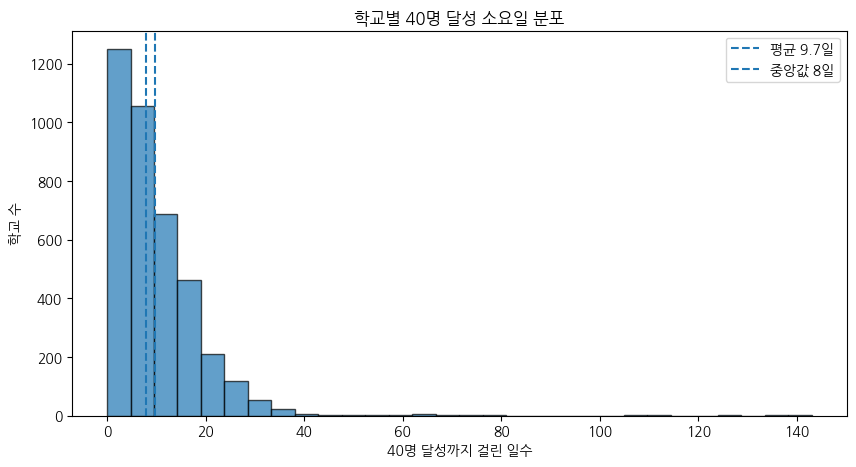

In [ ]:
import matplotlib.pyplot as plt

# 학교별 중복 제거 후 40명 달성 소요일만 추출
days_40 = network_base.loc[
    network_base['reached_40'],
    ['school_id', 'days_to_40']
].drop_duplicates('school_id')['days_to_40']

# 40명 달성까지 걸린 기간 분포
plt.figure(figsize=(10, 5))
plt.hist(days_40, bins=30, edgecolor='black', alpha=0.7)

# 평균과 중앙값 표시
plt.axvline(days_40.mean(), linestyle='--', label=f'평균 {days_40.mean():.1f}일')
plt.axvline(days_40.median(), linestyle='--', label=f'중앙값 {days_40.median():.0f}일')

plt.title('학교별 40명 달성 소요일 분포')
plt.xlabel('40명 달성까지 걸린 일수')
plt.ylabel('학교 수')
plt.legend()
plt.show()

며칠 이내에 몇 %가 40명을 달성했는지

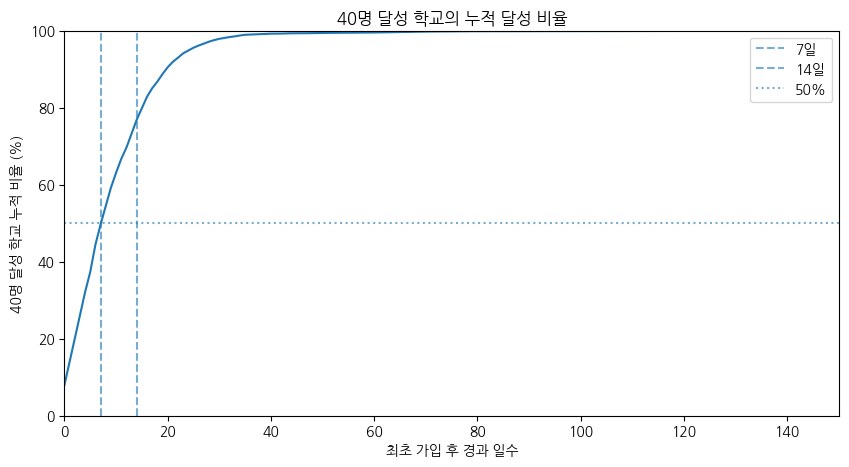

In [ ]:
# 소요일 기준 오름차순 정렬
days_sorted = days_40.sort_values()

# 누적 달성 학교 비율
cumulative_ratio = (
    days_sorted.rank(method='max') / len(days_sorted) * 100
)

plt.figure(figsize=(10, 5))
plt.plot(days_sorted, cumulative_ratio)

# 주요 기준선
plt.axvline(7, linestyle='--', alpha=0.6, label='7일')
plt.axvline(14, linestyle='--', alpha=0.6, label='14일')
plt.axhline(50, linestyle=':', alpha=0.6, label='50%')

plt.title('40명 달성 학교의 누적 달성 비율')
plt.xlabel('최초 가입 후 경과 일수')
plt.ylabel('40명 달성 학교 누적 비율 (%)')
plt.xlim(left=0)
plt.ylim(0, 100)
plt.legend()
plt.show()

40명 달성 학교의 절반이 약 8일 이내에 임계점을 통과했다

## 40명 달성 못한 학교들의 특징과 지표 확인 EDA

In [ ]:
# 지역별 40명 달성률

# 학교 주소에서 시·도 추출
network_base['region'] = network_base['school_address'].str.split().str[0]

# 시·도 명칭 간단하게 통일
network_base['region'] = network_base['region'].replace({
    '서울특별시': '서울', '부산광역시': '부산', '대구광역시': '대구',
    '인천광역시': '인천', '광주광역시': '광주', '대전광역시': '대전',
    '울산광역시': '울산', '세종특별자치시': '세종',
    '경기도': '경기', '강원특별자치도': '강원', '강원도': '강원',
    '충청북도': '충북', '충청남도': '충남',
    '전북특별자치도': '전북', '전라북도': '전북',
    '전라남도': '전남', '경상북도': '경북', '경상남도': '경남',
    '제주특별자치도': '제주'
})

# 지역별 학교 수 / 40명 달성 학교 수 / 달성률
(
    network_base[
        ['school_id', 'region', 'reached_40']
    ]
    .drop_duplicates('school_id')
    .groupby('region')
    .agg(
        school_count=('school_id', 'count'),
        reached_40_count=('reached_40', 'sum'),
        reached_40_rate=('reached_40', 'mean')
    )
    .assign(reached_40_rate=lambda x: (x['reached_40_rate'] * 100).round(2))
    .sort_values('reached_40_rate', ascending=False)
)

,school_count,reached_40_count,reached_40_rate
region,,,
대한민국,1,1,100.00
대구,225,206,91.56
울산,121,105,86.78
인천,270,230,85.19
부산,318,266,83.65
광주,161,131,81.37
경기,1158,925,79.88
대전,153,116,75.82
충북,206,149,72.33


In [ ]:
# 지역이 '대한민국'으로 잡히거나 지역 추출이 안 된 행 확인
network_base.loc[
    (network_base['region'] == '대한민국') | (network_base['region'].isna()),
    ['user_id', 'school_id', 'school_address', 'region', 'school_type']
]

,user_id,school_id,school_address,region,school_type
113043,967337,2941.0,대한민국 강원도 철원군,대한민국,H
245200,1110347,2941.0,대한민국 강원도 철원군,대한민국,H
364733,1240400,2941.0,대한민국 강원도 철원군,대한민국,H
380007,1257093,2941.0,대한민국 강원도 철원군,대한민국,H
380346,1257479,2941.0,대한민국 강원도 철원군,대한민국,H
381745,1259021,2941.0,대한민국 강원도 철원군,대한민국,H
384801,1262444,2941.0,대한민국 강원도 철원군,대한민국,H
397230,1276131,2941.0,대한민국 강원도 철원군,대한민국,H
433853,1316087,2941.0,대한민국 강원도 철원군,대한민국,H
451663,1335743,2941.0,대한민국 강원도 철원군,대한민국,H


In [ ]:
# 지역 추출이 비정상적인 학교 3개 확인
network_base.loc[
    network_base['region'].isin(['대한민국', '-']),
    ['school_id', 'school_address', 'region', 'school_type']
].drop_duplicates('school_id')

,school_id,school_address,region,school_type
113043,2941.0,대한민국 강원도 철원군,대한민국,H
661894,5948.0,-,-,H
672760,5949.0,-,-,H


In [ ]:
# '대한민국 강원도 ...' 주소의 지역 보정
network_base.loc[
    network_base['region'] == '대한민국',
    'region'
] = '강원'

In [ ]:
# 주소 정보가 없는 학교는 지역 결측으로 처리
network_base.loc[
    network_base['region'] == '-',
    'region'
] = pd.NA

In [ ]:
# 지역 정보가 있는 학교만 지역별 40명 달성률 계산
(
    network_base.dropna(subset=['region'])
    [['school_id', 'region', 'reached_40']]
    .drop_duplicates('school_id')
    .groupby('region')
    .agg(
        school_count=('school_id', 'count'),
        reached_40_count=('reached_40', 'sum'),
        reached_40_rate=('reached_40', 'mean')
    )
    .assign(reached_40_rate=lambda x: (x['reached_40_rate'] * 100).round(2))
    .sort_values('reached_40_rate', ascending=False)
)

,school_count,reached_40_count,reached_40_rate
region,,,
대구,225,206,91.56
울산,121,105,86.78
인천,270,230,85.19
부산,318,266,83.65
광주,161,131,81.37
경기,1158,925,79.88
대전,153,116,75.82
충북,206,149,72.33
충남,348,238,68.39


In [ ]:
# 중학교·고등학교별 40명 달성률

# 학교 유형별 40명 달성률
(
    network_base[
        ['school_id', 'school_type', 'reached_40']
    ]
    .drop_duplicates('school_id')
    .groupby('school_type')
    .agg(
        school_count=('school_id', 'count'),
        reached_40_count=('reached_40', 'sum'),
        reached_40_rate=('reached_40', 'mean')
    )
    .assign(reached_40_rate=lambda x: (x['reached_40_rate'] * 100).round(2))
)

,school_count,reached_40_count,reached_40_rate
school_type,,,
H,2457,2041,83.07
M,3093,1855,59.97


### 40명 미달 학교의 가입자가 몇명에서 멈췄는지

In [ ]:
# 40명 미달 학교의 최종 가입자 수 분포
network_base.loc[
    ~network_base['reached_40'],
    ['school_id', 'school_user_count']
].drop_duplicates('school_id')['school_user_count'].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
)

,school_user_count
count,1654.000000
mean,13.045949
std,10.483372
min,1.000000
10%,1.000000
25%,4.000000
50%,11.000000
75%,20.000000
90%,29.000000
max,39.000000


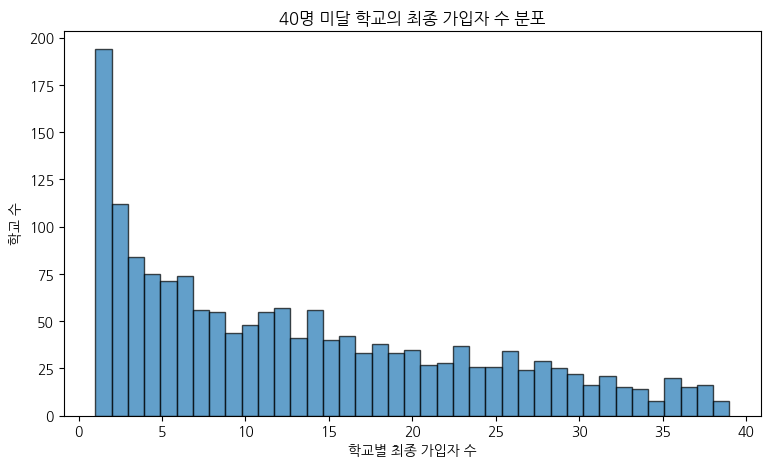

In [ ]:
# 40명 미달 학교의 최종 가입자 수 히스토그램
plt.figure(figsize=(9, 5))

network_base.loc[
    ~network_base['reached_40'],
    ['school_id', 'school_user_count']
].drop_duplicates('school_id')['school_user_count'].plot(
    kind='hist',
    bins=39,
    edgecolor='black',
    alpha=0.7
)

plt.title('40명 미달 학교의 최종 가입자 수 분포')
plt.xlabel('학교별 최종 가입자 수')
plt.ylabel('학교 수')
plt.xticks(range(0, 41, 5))
plt.show()

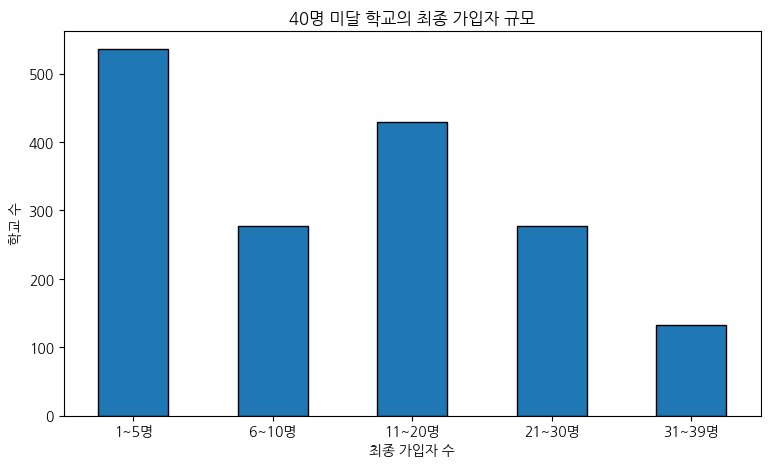

In [ ]:
# 미달 학교를 최종 가입자 수에 따라 구간화
miss_group = pd.cut(
    network_base.loc[
        ~network_base['reached_40'],
        ['school_id', 'school_user_count']
    ].drop_duplicates('school_id')['school_user_count'],
    bins=[0, 5, 10, 20, 30, 39],
    labels=['1~5명', '6~10명', '11~20명', '21~30명', '31~39명']
)

# 구간별 학교 수 시각화
miss_group.value_counts().sort_index().plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('40명 미달 학교의 최종 가입자 규모')
plt.xlabel('최종 가입자 수')
plt.ylabel('학교 수')
plt.xticks(rotation=0)
plt.show()

학교별 첫 3일 가입자 분포

In [ ]:
# 학교 최초 가입 후 3일 이내 가입 여부
network_base['joined_within_3d'] = (
    network_base['created_at'] - network_base['first_signup']
    <= pd.Timedelta(days=3)
)

# 학교별 초기 3일 가입자 수
network_base['signup_3d_count'] = (
    network_base.groupby('school_id')['joined_within_3d'].transform('sum')
)

# 40명 미달 학교의 초기 3일 가입자 수 분포
network_base.loc[
    ~network_base['reached_40'],
    ['school_id', 'signup_3d_count', 'school_user_count']
].drop_duplicates('school_id').describe()

,school_id,signup_3d_count,school_user_count
count,1654.000000,1654.000000,1654.000000
mean,2897.406288,3.514510,13.045949
std,1755.585755,4.373458,10.483372
min,9.000000,1.000000,1.000000
25%,1223.250000,1.000000,4.000000
50%,2870.500000,2.000000,11.000000
75%,4223.750000,4.000000,20.000000
max,5965.000000,28.000000,39.000000


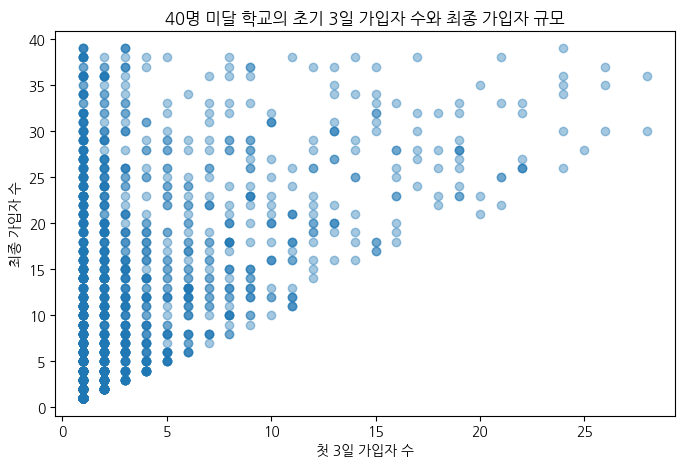

In [ ]:
# 40명 미달 학교에서 초기 확산과 최종 규모의 관계
miss_school = network_base.loc[
    ~network_base['reached_40'],
    ['school_id', 'signup_3d_count', 'school_user_count']
].drop_duplicates('school_id')

plt.figure(figsize=(8, 5))
plt.scatter(
    miss_school['signup_3d_count'],
    miss_school['school_user_count'],
    alpha=0.4
)

plt.title('40명 미달 학교의 초기 3일 가입자 수와 최종 가입자 규모')
plt.xlabel('첫 3일 가입자 수')
plt.ylabel('최종 가입자 수')
plt.show()

초기 3일 가입자 수가 많을수록 최종 가입자 규모도 커지는 경향은 보이지만, 초기 1~5명 구간에서도 최종 규모가 매우 넓게 분포한다.

In [ ]:
# 주변 10개 학교 평균거리 비교
# 주변 환경 밀도(?)

# 학교마다 주변 학교가 몇 개씩 기록되어 있는지 확인
nearby.groupby('school_id')['nearby_school_id'].nunique().describe()

,nearby_school_id
count,5562.000000
mean,8.507192
std,0.822518
min,3.000000
25%,8.000000
50%,9.000000
75%,9.000000
max,9.000000


### 40명 달성 여부별 주변 학교와의 거리 비교

In [ ]:
# 학교별 주변 학교 평균거리 계산 후 network_base에 추가
network_base['nearby_avg_distance'] = network_base['school_id'].map(
    nearby.groupby('school_id')['distance'].mean()
)

# 40명 달성 / 미달 학교 평균거리 비교
network_base[
    ['school_id', 'reached_40', 'nearby_avg_distance']
].drop_duplicates('school_id').groupby('reached_40')['nearby_avg_distance'].describe()

,count,mean,std,min,25%,50%,75%,max
reached_40,,,,,,,,
False,1651.0,0.076661,0.100458,0.006189,0.017856,0.065136,0.111634,1.652267
True,3896.0,0.037422,0.037944,0.000591,0.015122,0.021246,0.043414,0.365605


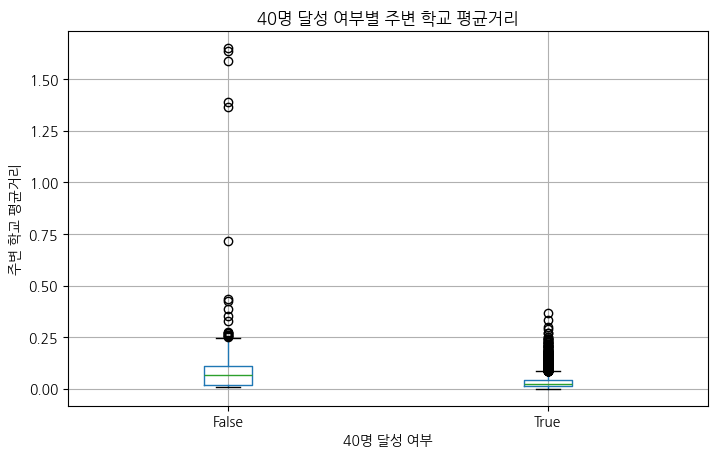

In [ ]:
# 40명 달성 여부별 주변 학교 평균거리 비교
network_base[
    ['school_id', 'reached_40', 'nearby_avg_distance']
].drop_duplicates('school_id').boxplot(
    column='nearby_avg_distance',
    by='reached_40',
    figsize=(8, 5)
)

plt.title('40명 달성 여부별 주변 학교 평균거리')
plt.suptitle('')
plt.xlabel('40명 달성 여부')
plt.ylabel('주변 학교 평균거리')
plt.show()

40명 미달 학교(False)는 달성 학교(True)보다 주변 학교 평균거리가 전반적으로 더 멀고 분산도 큰 편으로 보인다.

이는 주변 학교 밀도가 낮은 환경일수록 40명 네트워크 형성이 상대적으로 어려울 가능성을 시사하지만, 이상치가 크므로 중앙값 기준 비교와 통계 검정이 추가로 필요하다.

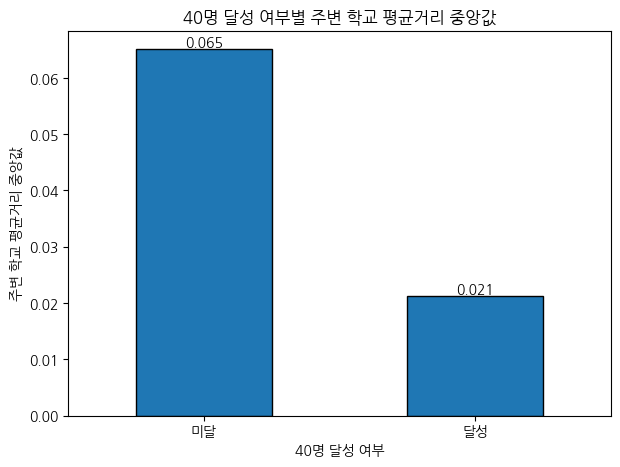

In [ ]:
# 학교별 중복 제거 후 40명 달성 여부별 주변 학교 평균거리 중앙값
distance_median = (
    network_base[
        ['school_id', 'reached_40', 'nearby_avg_distance']
    ]
    .drop_duplicates('school_id')
    .groupby('reached_40')['nearby_avg_distance']
    .median()
)

ax = distance_median.plot(kind='bar', figsize=(7, 5), edgecolor='black')

# 막대 위에 값 표시
for i, v in enumerate(distance_median):
    ax.text(i, v, f'{v:.3f}', ha='center', va='bottom')

plt.title('40명 달성 여부별 주변 학교 평균거리 중앙값')
plt.xlabel('40명 달성 여부')
plt.ylabel('주변 학교 평균거리 중앙값')
plt.xticks([0, 1], ['미달', '달성'], rotation=0)
plt.show()

In [ ]:
# 최초 20명 가입자가 몇 개 학급에 분산되어 있었는지 계산
network_base['first20_class_count'] = network_base['school_id'].map(
    network_base[
        (network_base['school_user_count'] >= 20) &
        (network_base['join_order'] <= 20)
    ]
    .groupby('school_id')['group_id']
    .nunique()
)

# 20명 이상 가입한 학교만 대상으로 40명 달성 여부별 비교
network_base.loc[
    network_base['school_user_count'] >= 20,
    ['school_id', 'reached_40', 'first20_class_count']
].drop_duplicates('school_id').groupby('reached_40')['first20_class_count'].describe()

,count,mean,std,min,25%,50%,75%,max
reached_40,,,,,,,,
False,446.0,8.163677,3.450143,1.0,5.25,8.0,11.0,17.0
True,3896.0,8.937115,2.571274,2.0,7.00,9.0,11.0,18.0


### 40명 달성 여부별 한 학급에 많이 몰렸나?

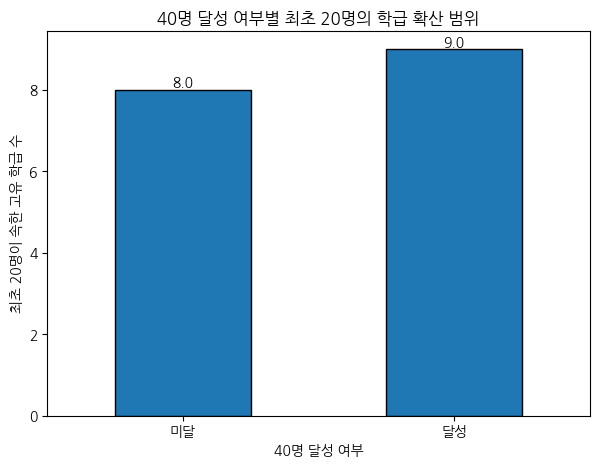

In [ ]:
# 40명 달성 여부별 최초 20명의 학급 다양성 중앙값
class_median = (
    network_base.loc[
        network_base['school_user_count'] >= 20,
        ['school_id', 'reached_40', 'first20_class_count']
    ]
    .drop_duplicates('school_id')
    .groupby('reached_40')['first20_class_count']
    .median()
)

ax = class_median.plot(kind='bar', figsize=(7, 5), edgecolor='black')

for i, v in enumerate(class_median):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')

plt.title('40명 달성 여부별 최초 20명의 학급 확산 범위')
plt.xlabel('40명 달성 여부')
plt.ylabel('최초 20명이 속한 고유 학급 수')
plt.xticks([0, 1], ['미달', '달성'], rotation=0)
plt.show()

40명 달성 학교는 최초 20명이 중앙값 9개 학급에 분산된 반면, 미달 학교는 8개 학급으로 초기 가입자가 조금 더 넓게 퍼진 학교에서 40명 달성 가능성이 높은 경향이 보였다.

다만 차이가 1개 학급 수준이고 분포도 많이 겹치니 핵심 요인은 아닌 것으로 보인다

-> 단순히 몇 개 반에 퍼졌는지보다, 최초 20명이 특정 한 반에 얼마나 몰렸는지

In [ ]:
# 최초 20명 중 가장 많은 가입자가 속한 한 학급의 비율 계산
network_base['first20_topclass_share'] = network_base['school_id'].map(
    network_base.loc[
        (network_base['school_user_count'] >= 20) &
        (network_base['join_order'] <= 20)
    ]
    .groupby(['school_id', 'group_id'])
    .size()
    .groupby(level=0)
    .max()
    .div(20)
)

# 40명 달성 여부별 초기 한 학급 집중도 비교
network_base.loc[
    network_base['school_user_count'] >= 20,
    ['school_id', 'reached_40', 'first20_topclass_share']
].drop_duplicates('school_id').groupby('reached_40')['first20_topclass_share'].describe()

,count,mean,std,min,25%,50%,75%,max
reached_40,,,,,,,,
False,446.0,0.304933,0.155637,0.1,0.2,0.25,0.3875,1.0
True,3896.0,0.273755,0.102628,0.1,0.2,0.25,0.3000,0.8


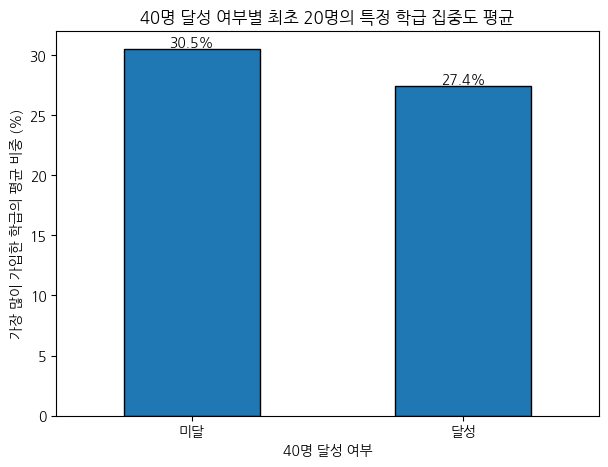

In [ ]:
# 40명 달성 여부별 최초 20명의 한 학급 집중도 평균
topclass_mean = (
    network_base.loc[
        network_base['school_user_count'] >= 20,
        ['school_id', 'reached_40', 'first20_topclass_share']
    ]
    .drop_duplicates('school_id')
    .groupby('reached_40')['first20_topclass_share']
    .mean()
    .mul(100)
)

ax = topclass_mean.plot(kind='bar', figsize=(7, 5), edgecolor='black')

# 막대 위에 평균 비율 표시
for i, v in enumerate(topclass_mean):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')

plt.title('40명 달성 여부별 최초 20명의 특정 학급 집중도 평균')
plt.xlabel('40명 달성 여부')
plt.ylabel('가장 많이 가입한 학급의 평균 비중 (%)')
plt.xticks([0, 1], ['미달', '달성'], rotation=0)
plt.show()

40명 미달 학교는 최초 20명 중 특정 학급에 몰린 비중이 평균 30.5%로, 달성 학교의 27.4%보다 높았다.

즉 초기 가입자가 한 학급에 더 집중된 학교일수록 학교 전체로의 네트워크 확산이 상대적으로 약한 경향이 보인다.

In [ ]:
# 40명 달성 여부별 학급 다양성 평균과 중앙값 비교
network_base.loc[
    network_base['school_user_count'] >= 20,
    ['school_id', 'reached_40', 'first20_class_count']
].drop_duplicates('school_id').groupby('reached_40')['first20_class_count'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
reached_40,,,,
False,446,8.163677,8.0,3.450143
True,3896,8.937115,9.0,2.571274


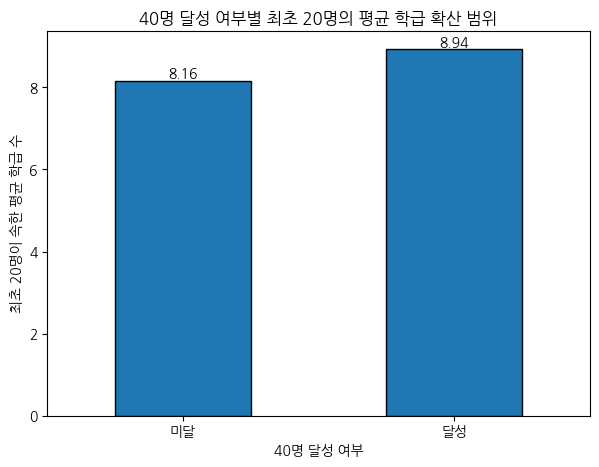

In [ ]:
# 최초 20명의 학급 다양성 평균 비교
class_mean = (
    network_base.loc[
        network_base['school_user_count'] >= 20,
        ['school_id', 'reached_40', 'first20_class_count']
    ]
    .drop_duplicates('school_id')
    .groupby('reached_40')['first20_class_count']
    .mean()
)

ax = class_mean.plot(kind='bar', figsize=(7, 5), edgecolor='black')

for i, v in enumerate(class_mean):
    ax.text(i, v, f'{v:.2f}', ha='center', va='bottom')

plt.title('40명 달성 여부별 최초 20명의 평균 학급 확산 범위')
plt.xlabel('40명 달성 여부')
plt.ylabel('최초 20명이 속한 평균 학급 수')
plt.xticks([0, 1], ['미달', '달성'], rotation=0)
plt.show()

In [ ]:
from scipy.stats import ttest_ind

# 학교 단위 특정 학급 집중도
miss = network_base.loc[
    (network_base['school_user_count'] >= 20) & (~network_base['reached_40']),
    ['school_id', 'first20_topclass_share']
].drop_duplicates('school_id')['first20_topclass_share'].dropna()

reach = network_base.loc[
    (network_base['school_user_count'] >= 20) & (network_base['reached_40']),
    ['school_id', 'first20_topclass_share']
].drop_duplicates('school_id')['first20_topclass_share'].dropna()

ttest_ind(miss, reach, equal_var=False)

TtestResult(statistic=np.float64(4.129044535907677), pvalue=np.float64(4.281721409854087e-05), df=np.float64(490.26458979258507))

t = 4.129

p = 0.0000428

In [ ]:
# 평균 차이와 Cohen's d
mean_diff = (miss.mean() - reach.mean()) * 100

pooled_std = (
    ((len(miss) - 1) * miss.var() + (len(reach) - 1) * reach.var())
    / (len(miss) + len(reach) - 2)
) ** 0.5

cohens_d = (miss.mean() - reach.mean()) / pooled_std

pd.Series({
    '평균 차이(%p)': mean_diff,
    "Cohen's d": cohens_d
})

,0
평균 차이(%p),3.117760
Cohen's d,0.285371


애초에 미달 학교가 학급 수가 적어서 한 학급에 몰린 것은 아닐까?

In [ ]:
# 학교별 전체 학급(group) 수
network_base['school_class_count'] = network_base['school_id'].map(
    groups.groupby('school_id')['id'].nunique()
)

# 최소 20명 가입 학교에서 40명 달성 여부별 전체 학급 수 비교
network_base.loc[
    network_base['school_user_count'] >= 20,
    ['school_id', 'reached_40', 'school_class_count']
].drop_duplicates('school_id').groupby('reached_40')['school_class_count'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
reached_40,,,,
False,446,10.186099,10.0,4.924042
True,3896,19.082136,19.0,7.658865


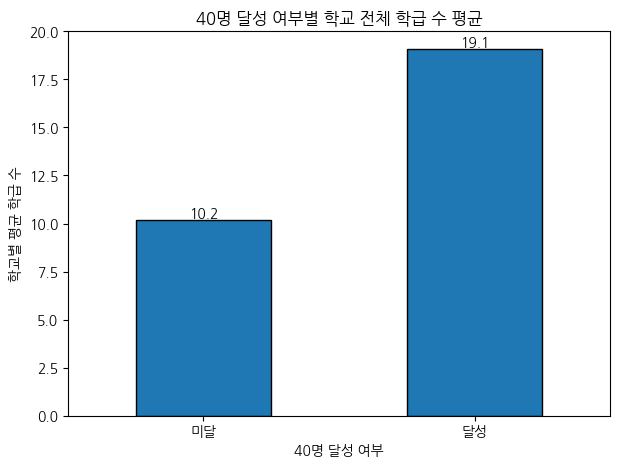

In [ ]:
# 40명 달성 여부별 학교 전체 학급 수 평균
class_count_mean = (
    network_base.loc[
        network_base['school_user_count'] >= 20,
        ['school_id', 'reached_40', 'school_class_count']
    ]
    .drop_duplicates('school_id')
    .groupby('reached_40')['school_class_count']
    .mean()
)

ax = class_count_mean.plot(kind='bar', figsize=(7, 5), edgecolor='black')

for i, v in enumerate(class_count_mean):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')

plt.title('40명 달성 여부별 학교 전체 학급 수 평균')
plt.xlabel('40명 달성 여부')
plt.ylabel('학교별 평균 학급 수')
plt.xticks([0, 1], ['미달', '달성'], rotation=0)
plt.show()

#### 18~20반 제외하고 다시 확인

In [ ]:
# 18~20반 제외 후 학교별 실제 학급 수 계산
network_base['school_class_count'] = network_base['school_id'].map(
    groups.loc[
        ~groups['class_num'].isin([18, 19, 20])
    ].groupby('school_id')['id'].nunique()
)

# 40명 달성 여부별 전체 학급 수 비교
network_base.loc[
    network_base['school_user_count'] >= 20,
    ['school_id', 'reached_40', 'school_class_count']
].drop_duplicates('school_id').groupby('reached_40')['school_class_count'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
reached_40,,,,
False,446,9.968610,10.0,4.854642
True,3896,18.516427,18.0,7.603238


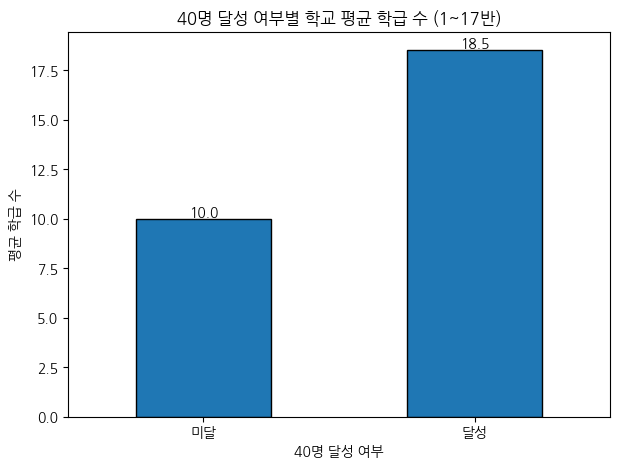

In [ ]:
# 달성 여부별 평균 학급 수
class_count_mean = (
    network_base.loc[
        network_base['school_user_count'] >= 20,
        ['school_id', 'reached_40', 'school_class_count']
    ]
    .drop_duplicates('school_id')
    .groupby('reached_40')['school_class_count']
    .mean()
)

ax = class_count_mean.plot(kind='bar', figsize=(7, 5), edgecolor='black')

for i, v in enumerate(class_count_mean):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')

plt.title('40명 달성 여부별 학교 평균 학급 수 (1~17반)')
plt.xlabel('40명 달성 여부')
plt.ylabel('평균 학급 수')
plt.xticks([0, 1], ['미달', '달성'], rotation=0)
plt.show()

In [ ]:
# 학교별 학급 수 범위 확인
network_base[['school_id', 'school_class_count']].drop_duplicates()['school_class_count'].describe()

,school_class_count
count,5546.000000
mean,14.710422
std,9.003385
min,1.000000
25%,8.000000
50%,14.000000
75%,21.000000
max,44.000000


In [ ]:
# 학급 수가 많은 학교의 학년-반 구성 확인
check_school = (
    network_base[['school_id', 'school_class_count']]
    .drop_duplicates()
    .sort_values('school_class_count', ascending=False)
    .iloc[0]['school_id']
)

network_base.loc[
    network_base['school_id'] == check_school,
    ['grade', 'class_num']
].drop_duplicates().sort_values(['grade', 'class_num'])

,grade,class_num
40431,1.0,1.0
42704,1.0,2.0
40206,1.0,3.0
35692,1.0,4.0
42276,1.0,5.0
42007,1.0,6.0
40221,1.0,7.0
49809,1.0,8.0
46471,1.0,9.0
60111,1.0,10.0


In [ ]:
# 최초 20명 중 1~17반만 대상으로
# 가장 많은 가입자가 속한 학급 비중 재계산
network_base['first20_topclass_share'] = network_base['school_id'].map(
    network_base.loc[
        (network_base['school_user_count'] >= 20) &
        (network_base['join_order'] <= 20) &
        (~network_base['class_num'].isin([18, 19, 20]))
    ]
    .groupby(['school_id', 'group_id'])
    .size()
    .groupby(level=0)
    .max()
    .div(20)
)

In [ ]:
# 최초 20명 중 18~20반에 해당하는 유저 수
network_base.loc[
    (network_base['join_order'] <= 20) &
    (network_base['class_num'].isin([18, 19, 20])),
    'user_id'
].nunique()

417

In [ ]:
# 학급 분석에 사용할 유효 유저 여부
network_base['valid_class'] = ~network_base['class_num'].isin([18, 19, 20])

# 학교별 유효 학급 유저들의 가입 순서 재계산
network_base['valid_class_order'] = (
    network_base['valid_class']
    .groupby(network_base['school_id'])
    .cumsum()
)

# 학교별 유효 학급 유저 수
network_base['valid_class_count'] = (
    network_base.groupby('school_id')['valid_class'].transform('sum')
)

In [ ]:
# 유효 학급 기준 최초 20명 중 특정 학급 최대 집중 비율
network_base['first20_topclass_share'] = network_base['school_id'].map(
    network_base.loc[
        network_base['valid_class'] &
        (network_base['valid_class_order'] <= 20) &
        (network_base['valid_class_count'] >= 20)
    ]
    .groupby(['school_id', 'group_id'])
    .size()
    .groupby(level=0)
    .max()
    .div(20)
)

In [ ]:
# 40명 달성 여부별 특정 학급 집중도 평균
network_base.loc[
    network_base['valid_class_count'] >= 20,
    ['school_id', 'reached_40', 'first20_topclass_share']
].drop_duplicates('school_id').groupby('reached_40')['first20_topclass_share'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
reached_40,,,,
False,438,0.307534,0.25,0.156551
True,3896,0.273960,0.25,0.102380


In [ ]:
# 기존 최초 20명 중 18~20반 유저가 포함됐던 학교 수
network_base.loc[
    (network_base['join_order'] <= 20) &
    (network_base['class_num'].isin([18, 19, 20])),
    'school_id'
].nunique()

306

### 연락처

In [ ]:
# 연락처/초대 정보 테이블 불러오기
contacts = pd.read_csv(path / 'accounts_user_contacts_cleaned.csv')

contacts.head()

,id,contacts_count,invite_user_id_list,user_id
0,259,30,[],1167696
1,1756,79,[],863169
2,13742,21,[854615],857205
3,13754,29,[],851431
4,13756,28,[849318],855476


해당 전화번호를 가지고 있는 유저 수

In [ ]:
# contacts 컬럼명 먼저 확인
contacts.columns

Index(['id', 'contacts_count', 'invite_user_id_list', 'user_id'], dtype='object')

In [ ]:
# 연락처 정보가 존재하는 유저 여부
network_base['has_contacts'] = network_base['user_id'].isin(contacts['user_id'])

# 학교별 최초 10명 중 연락처 데이터가 있는 유저 수
network_base['first10_contacts_n'] = network_base['school_id'].map(
    network_base.loc[
        network_base['join_order'] <= 10
    ]
    .groupby('school_id')['has_contacts']
    .sum()
)

# 최초 10명 중 연락처 정보가 몇 명이나 확보됐는지 분포 확인
network_base[
    ['school_id', 'reached_40', 'first10_contacts_n']
].drop_duplicates('school_id').groupby('reached_40')['first10_contacts_n'].describe()

,count,mean,std,min,25%,50%,75%,max
reached_40,,,,,,,,
False,1654.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
True,3896.0,0.020277,0.433334,0.0,0.0,0.0,0.0,10.0


In [ ]:
# 유저별 contacts_count를 network_base에 매핑
network_base['contacts_count'] = network_base['user_id'].map(
    contacts.drop_duplicates('user_id').set_index('user_id')['contacts_count']
)

# 학교별 최초 10명 중 contacts 정보가 존재하는 유저들의 평균
network_base['first10_contacts_mean'] = network_base['school_id'].map(
    network_base.loc[
        (network_base['join_order'] <= 10) &
        (network_base['contacts_count'].notna())
    ]
    .groupby('school_id')['contacts_count']
    .mean()
)

# 40명 달성 여부별 비교
network_base[
    ['school_id', 'reached_40', 'first10_contacts_n', 'first10_contacts_mean']
].drop_duplicates('school_id').groupby('reached_40')[
    ['first10_contacts_n', 'first10_contacts_mean']
].describe()

first10_contacts_n                                                \
                        count      mean       std  min  25%  50%  75%   max   
reached_40                                                                    
False                  1654.0  0.000000  0.000000  0.0  0.0  0.0  0.0   0.0   
True                   3896.0  0.020277  0.433334  0.0  0.0  0.0  0.0  10.0   

           first10_contacts_mean                                         \
                           count       mean       std   min   25%   50%   
reached_40                                                                
False                        0.0        NaN       NaN   NaN   NaN   NaN   
True                         9.0  33.169753  6.303662  24.8  30.5  31.5   

                              
                  75%    max  
reached_40                    
False             NaN    NaN  
True        35.777778  46.25

In [ ]:
# contacts 테이블 존재 여부
network_base['has_contacts'] = network_base['user_id'].isin(contacts['user_id'])

# 40명 달성 여부별 contacts 기록 보유 유저 수와 비율
network_base.groupby('reached_40')['has_contacts'].agg(
    user_count='count',
    contacts_users='sum',
    contacts_rate='mean'
).assign(
    contacts_rate=lambda x: (x['contacts_rate'] * 100).round(2)
)

,user_count,contacts_users,contacts_rate
reached_40,,,
False,21578,0,0.00
True,655402,5063,0.77


In [ ]:
# contacts 기록이 1명이라도 존재하는 학교의 비율
network_base['school_has_contacts'] = (
    network_base.groupby('school_id')['has_contacts'].transform('max')
)

network_base[
    ['school_id', 'reached_40', 'school_has_contacts']
].drop_duplicates('school_id').groupby('reached_40')['school_has_contacts'].agg(
    school_count='count',
    contacts_school='sum',
    contacts_school_rate='mean'
).assign(
    contacts_school_rate=lambda x: (x['contacts_school_rate'] * 100).round(2)
)

,school_count,contacts_school,contacts_school_rate
reached_40,,,
False,1654,0,0.00
True,3896,10,0.26


In [ ]:
contacts.shape

(5063, 4)

#### contacts 기록이 존재하는 학교 10개의 특성

In [ ]:
# contacts 기록이 존재하는 학교 10개의 특성 확인
network_base.loc[
    network_base['school_has_contacts'],
    ['school_id', 'school_address', 'region', 'school_type',
     'student_count', 'school_user_count', 'reached_40']
].drop_duplicates('school_id').sort_values('school_user_count', ascending=False)

,school_id,school_address,region,school_type,student_count,school_user_count,reached_40
632,369.0,충청남도 아산시,충남,H,578.0,578,True
118814,1719.0,울산광역시 울주군,울산,H,550.0,551,True
12476,4516.0,경기도 화성시,경기,H,507.0,510,True
84886,5372.0,경기도 남양주시,경기,H,505.0,507,True
50452,5520.0,경기도 광명시,경기,M,500.0,500,True
395,271.0,충청남도 천안시 서북구,충남,H,491.0,492,True
4769,352.0,충청남도 아산시,충남,H,491.0,491,True
37867,1478.0,인천광역시 서구,인천,M,489.0,488,True
13342,4426.0,경상남도 거제시,경남,H,483.0,487,True
2886,5491.0,경기도 광주시,경기,H,486.0,486,True


In [ ]:
# contacts 기록 유저가 학교별로 몇 명씩 존재하는지 확인
network_base.loc[
    network_base['has_contacts'],
    ['school_id', 'school_address', 'region', 'user_id']
].groupby(
    ['school_id', 'school_address', 'region']
).agg(
    contacts_users=('user_id', 'nunique')
).sort_values('contacts_users', ascending=False)

,,,contacts_users
school_id,school_address,region,
369.0,충청남도 아산시,충남,568
1719.0,울산광역시 울주군,울산,550
4516.0,경기도 화성시,경기,509
5372.0,경기도 남양주시,경기,507
5520.0,경기도 광명시,경기,500
1478.0,인천광역시 서구,인천,488
4426.0,경상남도 거제시,경남,487
352.0,충청남도 아산시,충남,487
5491.0,경기도 광주시,경기,484


In [ ]:
# contacts 전체 유저 중 각 학교가 차지하는 비율
(
    network_base.loc[
        network_base['has_contacts'],
        ['school_id', 'user_id']
    ]
    .groupby('school_id')['user_id']
    .nunique()
    .sort_values(ascending=False)
    .div(network_base['has_contacts'].sum())
    .mul(100)
    .round(2)
)

,user_id
school_id,
369.0,11.22
1719.0,10.86
4516.0,10.05
5372.0,10.01
5520.0,9.88
1478.0,9.64
4426.0,9.62
352.0,9.62
5491.0,9.56


In [ ]:
# 해당 10개 학교에서 전체 가입자 중 contacts 기록 유저의 비율
network_base.loc[
    network_base['school_has_contacts'],
    ['school_id', 'school_address', 'school_user_count', 'has_contacts']
].groupby(
    ['school_id', 'school_address', 'school_user_count']
).agg(
    contacts_users=('has_contacts', 'sum')
).assign(
    contacts_rate=lambda x:
        (x['contacts_users'] / x.index.get_level_values('school_user_count') * 100).round(2)
).sort_values('contacts_rate', ascending=False)

,,,contacts_users,contacts_rate
school_id,school_address,school_user_count,,
4426.0,경상남도 거제시,487,487,100.00
1478.0,인천광역시 서구,488,488,100.00
5520.0,경기도 광명시,500,500,100.00
5372.0,경기도 남양주시,507,507,100.00
1719.0,울산광역시 울주군,551,550,99.82
4516.0,경기도 화성시,510,509,99.80
5491.0,경기도 광주시,486,484,99.59
352.0,충청남도 아산시,491,487,99.19
369.0,충청남도 아산시,578,568,98.27


In [ ]:
# 학교별 10번째, 20번째 가입 시점 추가
network_base['signup_10_at'] = network_base['school_id'].map(
    network_base.loc[network_base['join_order'] == 10]
    .set_index('school_id')['created_at']
)

network_base['signup_20_at'] = network_base['school_id'].map(
    network_base.loc[network_base['join_order'] == 20]
    .set_index('school_id')['created_at']
)

# contacts가 존재하는 10개 학교의 가입 흐름 확인
network_base.loc[
    network_base['school_has_contacts'],
    [
        'school_id', 'school_address', 'region', 'school_type',
        'school_user_count', 'first_signup',
        'signup_10_at', 'signup_20_at', 'reached_40_at',
        'days_to_40'
    ]
].drop_duplicates('school_id').sort_values('first_signup')

,school_id,school_address,region,school_type,school_user_count,first_signup,signup_10_at,signup_20_at,reached_40_at,days_to_40
395,271.0,충청남도 천안시 서북구,충남,H,492,2023-04-19 09:06:00.719792,2023-04-28 02:56:34.379981,2023-04-28 03:10:14.674737,2023-04-28 03:43:18.503902,8.0
632,369.0,충청남도 아산시,충남,H,578,2023-04-19 15:10:56.560337,2023-04-25 02:45:25.205474,2023-05-02 00:33:04.700031,2023-05-02 22:44:27.267798,13.0
2886,5491.0,경기도 광주시,경기,H,486,2023-04-22 13:39:28.230920,2023-04-30 14:40:48.092353,2023-05-06 02:38:52.901159,2023-05-07 02:57:28.039304,14.0
4769,352.0,충청남도 아산시,충남,H,491,2023-04-24 04:10:12.095185,2023-05-03 09:50:33.722620,2023-05-04 03:01:10.866364,2023-05-05 04:07:00.053881,10.0
12476,4516.0,경기도 화성시,경기,H,510,2023-04-29 14:23:17.790839,2023-05-01 22:50:12.539881,2023-05-02 13:14:16.580825,2023-05-02 15:17:04.497555,3.0
13342,4426.0,경상남도 거제시,경남,H,487,2023-04-29 16:06:03.134614,2023-05-13 05:45:43.189614,2023-05-13 13:22:58.102672,2023-05-16 00:18:41.426463,16.0
37867,1478.0,인천광역시 서구,인천,M,488,2023-05-05 10:51:32.513375,2023-05-06 13:07:58.837165,2023-05-06 13:30:59.751649,2023-05-06 14:18:58.057918,1.0
50452,5520.0,경기도 광명시,경기,M,500,2023-05-06 08:51:06.377706,2023-05-07 02:48:58.487242,2023-05-07 13:02:48.571752,2023-05-08 13:49:27.604223,2.0
84886,5372.0,경기도 남양주시,경기,H,507,2023-05-07 02:33:46.412013,2023-05-10 12:00:57.274850,2023-05-10 13:08:11.266067,2023-05-10 23:47:35.094548,3.0
118814,1719.0,울산광역시 울주군,울산,H,551,2023-05-07 14:15:09.397548,2023-05-10 22:32:55.649556,2023-05-12 13:47:43.735216,2023-05-13 08:00:50.712386,5.0


In [ ]:
# 학교별 마지막 가입일
network_base['last_signup'] = (
    network_base.groupby('school_id')['created_at'].transform('max')
)

network_base.loc[
    network_base['school_has_contacts'],
    [
        'school_id', 'region', 'school_address',
        'school_user_count', 'first_signup',
        'signup_10_at', 'signup_20_at',
        'reached_40_at', 'last_signup', 'days_to_40'
    ]
].drop_duplicates('school_id').sort_values('first_signup')

,school_id,region,school_address,school_user_count,first_signup,signup_10_at,signup_20_at,reached_40_at,last_signup,days_to_40
395,271.0,충남,충청남도 천안시 서북구,492,2023-04-19 09:06:00.719792,2023-04-28 02:56:34.379981,2023-04-28 03:10:14.674737,2023-04-28 03:43:18.503902,2023-09-13 16:06:38.453835,8.0
632,369.0,충남,충청남도 아산시,578,2023-04-19 15:10:56.560337,2023-04-25 02:45:25.205474,2023-05-02 00:33:04.700031,2023-05-02 22:44:27.267798,2024-04-22 04:54:45.332573,13.0
2886,5491.0,경기,경기도 광주시,486,2023-04-22 13:39:28.230920,2023-04-30 14:40:48.092353,2023-05-06 02:38:52.901159,2023-05-07 02:57:28.039304,2023-11-18 15:12:55.132769,14.0
4769,352.0,충남,충청남도 아산시,491,2023-04-24 04:10:12.095185,2023-05-03 09:50:33.722620,2023-05-04 03:01:10.866364,2023-05-05 04:07:00.053881,2023-09-23 08:52:16.138685,10.0
12476,4516.0,경기,경기도 화성시,510,2023-04-29 14:23:17.790839,2023-05-01 22:50:12.539881,2023-05-02 13:14:16.580825,2023-05-02 15:17:04.497555,2023-09-20 15:30:13.114964,3.0
13342,4426.0,경남,경상남도 거제시,487,2023-04-29 16:06:03.134614,2023-05-13 05:45:43.189614,2023-05-13 13:22:58.102672,2023-05-16 00:18:41.426463,2023-06-18 03:14:36.399002,16.0
37867,1478.0,인천,인천광역시 서구,488,2023-05-05 10:51:32.513375,2023-05-06 13:07:58.837165,2023-05-06 13:30:59.751649,2023-05-06 14:18:58.057918,2023-08-01 11:51:13.811964,1.0
50452,5520.0,경기,경기도 광명시,500,2023-05-06 08:51:06.377706,2023-05-07 02:48:58.487242,2023-05-07 13:02:48.571752,2023-05-08 13:49:27.604223,2024-03-19 12:53:37.705774,2.0
84886,5372.0,경기,경기도 남양주시,507,2023-05-07 02:33:46.412013,2023-05-10 12:00:57.274850,2023-05-10 13:08:11.266067,2023-05-10 23:47:35.094548,2023-12-06 14:44:01.270373,3.0
118814,1719.0,울산,울산광역시 울주군,551,2023-05-07 14:15:09.397548,2023-05-10 22:32:55.649556,2023-05-12 13:47:43.735216,2023-05-13 08:00:50.712386,2024-03-06 12:00:24.208601,5.0


In [ ]:
# 투표 유저 / contacts 유저 ID
voter_ids = set(account_user['user_id'].dropna().unique())
contact_ids = set(contacts['user_id'].dropna().unique())

overlap_ids = voter_ids & contact_ids

pd.Series({
    '투표 유저 수': len(voter_ids),
    'contacts 유저 수': len(contact_ids),
    '겹치는 유저 수': len(overlap_ids),
    '투표자 중 contacts 포함 비율(%)': round(len(overlap_ids) / len(voter_ids) * 100, 2),
    'contacts 중 투표자 비율(%)': round(len(overlap_ids) / len(contact_ids) * 100, 2),
    '투표에만 있는 유저': len(voter_ids - contact_ids),
    'contacts에만 있는 유저': len(contact_ids - voter_ids)
})

,0
투표 유저 수,4849.00
contacts 유저 수,5063.00
겹치는 유저 수,4824.00
투표자 중 contacts 포함 비율(%),99.48
contacts 중 투표자 비율(%),95.28
투표에만 있는 유저,25.00
contacts에만 있는 유저,239.00


In [ ]:
# UQR 투표 여부 추가
network_base['is_voter'] = network_base['user_id'].isin(voter_ids)

# contacts 기록이 존재하는 10개 학교의 투표자 수 확인
network_base.loc[
    network_base['school_has_contacts'],
    ['school_id', 'school_address', 'region', 'user_id', 'is_voter']
].groupby(
    ['school_id', 'school_address', 'region']
).agg(
    school_users=('user_id', 'nunique'),
    voter_users=('is_voter', 'sum')
).assign(
    voter_rate=lambda x: (x['voter_users'] / x['school_users'] * 100).round(2)
).sort_values('voter_users', ascending=False)

,,,school_users,voter_users,voter_rate
school_id,school_address,region,,,
1719.0,울산광역시 울주군,울산,551,541,98.19
369.0,충청남도 아산시,충남,578,537,92.91
5372.0,경기도 남양주시,경기,507,485,95.66
4516.0,경기도 화성시,경기,510,479,93.92
5520.0,경기도 광명시,경기,500,478,95.60
4426.0,경상남도 거제시,경남,487,470,96.51
1478.0,인천광역시 서구,인천,488,467,95.70
271.0,충청남도 천안시 서북구,충남,492,467,94.92
5491.0,경기도 광주시,경기,486,463,95.27


In [ ]:
# contacts 학교 10곳에 속한 전체 투표자 수
voters_in_10schools = network_base.loc[
    network_base['school_has_contacts'] & network_base['is_voter'],
    'user_id'
].nunique()

pd.Series({
    '전체 투표자': len(voter_ids),
    '10개 학교 투표자': voters_in_10schools,
    '10개 학교 포함 비율(%)': round(voters_in_10schools / len(voter_ids) * 100, 2)
})

,0
전체 투표자,4849.0
10개 학교 투표자,4849.0
10개 학교 포함 비율(%),100.0


In [ ]:
# contacts에는 있지만 UQR 투표 기록은 없는 유저
contact_only_ids = contact_ids - voter_ids

In [ ]:
# contacts-only 유저의 학교, 가입일, 상태 확인
network_base.loc[
    network_base['user_id'].isin(contact_only_ids),
    ['user_id', 'school_id', 'region', 'created_at',
     'school_user_count', 'reached_40', 'ban_status']
].head(20)

,user_id,school_id,region,created_at,school_user_count,reached_40,ban_status
9210,850120,271.0,충남,2023-04-28 13:39:23.716808,492,True,N
9283,850216,271.0,충남,2023-04-28 13:59:39.199699,492,True,N
9381,850339,271.0,충남,2023-04-28 14:30:31.780250,492,True,NB
13603,855549,271.0,충남,2023-04-29 16:46:45.795854,492,True,N
13982,856027,271.0,충남,2023-04-29 23:37:51.140375,492,True,N
15652,858172,271.0,충남,2023-04-30 09:38:45.596003,492,True,NB
18476,861753,271.0,충남,2023-04-30 16:11:25.832536,492,True,N
18585,861900,271.0,충남,2023-04-30 16:38:03.655030,492,True,N
21831,865922,271.0,충남,2023-05-01 12:54:05.690671,492,True,N
22365,866576,271.0,충남,2023-05-01 13:59:08.734822,492,True,N


In [ ]:
# contacts-only 239명의 학교 분포
network_base.loc[
    network_base['user_id'].isin(contact_only_ids),
    ['school_id', 'school_address', 'region', 'user_id']
].groupby(
    ['school_id', 'school_address', 'region']
)['user_id'].nunique().sort_values(ascending=False)

,,,user_id
school_id,school_address,region,
369.0,충청남도 아산시,충남,41
4516.0,경기도 화성시,경기,30
352.0,충청남도 아산시,충남,29
271.0,충청남도 천안시 서북구,충남,24
5491.0,경기도 광주시,경기,23
5372.0,경기도 남양주시,경기,22
5520.0,경기도 광명시,경기,22
1478.0,인천광역시 서구,인천,21
4426.0,경상남도 거제시,경남,17


239명이 10개중 1~2개의 학교에 몰리지는 않음

In [ ]:
# 출석 테이블 불러오기
attendance = pd.read_csv(
    path / 'accounts_attendance_clean.csv'
)

# 출석 기록 존재 여부
network_base['has_attendance'] = network_base['user_id'].isin(
    attendance['user_id']
)

# contacts-only vs 실제 투표자의 출석 기록 보유율
network_base.loc[
    network_base['user_id'].isin(contact_ids),
    ['user_id', 'is_voter', 'has_attendance']
].drop_duplicates('user_id').groupby('is_voter')['has_attendance'].agg(
    user_count='count',
    attendance_users='sum',
    attendance_rate='mean'
).assign(
    attendance_rate=lambda x: (x['attendance_rate'] * 100).round(2)
)

,user_count,attendance_users,attendance_rate
is_voter,,,
False,239,9,3.77
True,4824,2057,42.64


In [ ]:
# 유저별 출석 일수 계산
network_base['attendance_count'] = network_base['user_id'].map(
    attendance.groupby('user_id').size()
).fillna(0)

# contacts 유저 중 투표자 / 비투표자 활동량 비교
network_base.loc[
    network_base['user_id'].isin(contact_ids),
    ['user_id', 'is_voter', 'attendance_count']
].drop_duplicates('user_id').groupby('is_voter')['attendance_count'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
is_voter,,,,
False,239,0.075314,0.0,0.669392
True,4824,2.450871,0.0,5.920238


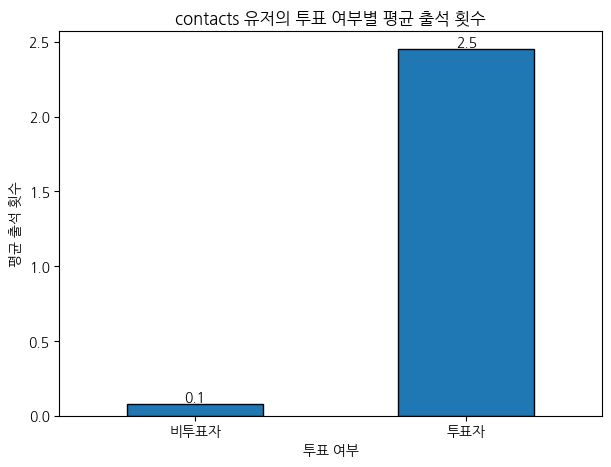

In [ ]:
# 투표 여부별 평균 출석 횟수
attendance_mean = (
    network_base.loc[
        network_base['user_id'].isin(contact_ids),
        ['user_id', 'is_voter', 'attendance_count']
    ]
    .drop_duplicates('user_id')
    .groupby('is_voter')['attendance_count']
    .mean()
)

ax = attendance_mean.plot(kind='bar', figsize=(7, 5), edgecolor='black')

for i, v in enumerate(attendance_mean):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')

plt.title('contacts 유저의 투표 여부별 평균 출석 횟수')
plt.xlabel('투표 여부')
plt.ylabel('평균 출석 횟수')
plt.xticks([0, 1], ['비투표자', '투표자'], rotation=0)
plt.show()

In [ ]:
# 앱 전체 최초 가입자와 소속 학교 확인
base.sort_values('created_at')[
    ['user_id', 'school_id', 'school_address', 'school_type', 'created_at']
].head(1)

,user_id,school_id,school_address,school_type,created_at
0,831962,1.0,NaN,NaN,2023-03-29 05:18:56.162368


In [ ]:
# 학교별 최초 가입자를 뽑은 뒤, 가장 먼저 등장한 학교 10곳 확인
(
    network_base
    .sort_values(['created_at', 'user_id'])
    .drop_duplicates('school_id')
    .head(10)[
        ['user_id', 'school_id', 'school_address', 'region',
         'school_type', 'created_at', 'school_has_contacts']
    ]
)

,user_id,school_id,school_address,region,school_type,created_at,school_has_contacts
10,833024,5464.0,경기도 군포시,경기,H,2023-03-31 09:05:51.903699,False
11,833041,314.0,충청남도 천안시 동남구,충남,H,2023-03-31 14:32:36.425315,False
12,833112,281.0,충청남도 천안시 서북구,충남,H,2023-03-31 15:55:48.870381,False
13,833113,272.0,충청남도 천안시 서북구,충남,H,2023-03-31 15:56:52.300066,False
20,833303,289.0,충청남도 천안시 서북구,충남,H,2023-03-31 16:01:40.796317,False
35,833763,4523.0,경기도 화성시,경기,H,2023-04-01 00:24:59.710901,False
39,833974,268.0,충청남도 천안시 서북구,충남,H,2023-04-01 03:17:53.202598,False
45,834162,4732.0,경기도 의왕시,경기,H,2023-04-01 11:26:23.269860,False
54,834687,10.0,충청북도 충주시,충북,M,2023-04-04 03:19:12.336682,False
55,834771,2932.0,부산광역시 강서구,부산,M,2023-04-04 03:23:46.718202,False


In [ ]:
# 가입이 가장 빨랐던 학교 10곳 + 순위
(
    network_base
    .sort_values(['created_at', 'user_id'])
    .drop_duplicates('school_id')
    .head(10)[
        ['user_id', 'school_id', 'school_address', 'region',
         'school_type', 'created_at', 'school_has_contacts']
    ]
    .reset_index(drop=True)
    .rename_axis('가입_학교_순위')
    .reset_index()
    .assign(가입_학교_순위=lambda x: x['가입_학교_순위'] + 1)
)

,가입_학교_순위,user_id,school_id,school_address,region,school_type,created_at,school_has_contacts
0,1,833024,5464.0,경기도 군포시,경기,H,2023-03-31 09:05:51.903699,False
1,2,833041,314.0,충청남도 천안시 동남구,충남,H,2023-03-31 14:32:36.425315,False
2,3,833112,281.0,충청남도 천안시 서북구,충남,H,2023-03-31 15:55:48.870381,False
3,4,833113,272.0,충청남도 천안시 서북구,충남,H,2023-03-31 15:56:52.300066,False
4,5,833303,289.0,충청남도 천안시 서북구,충남,H,2023-03-31 16:01:40.796317,False
5,6,833763,4523.0,경기도 화성시,경기,H,2023-04-01 00:24:59.710901,False
6,7,833974,268.0,충청남도 천안시 서북구,충남,H,2023-04-01 03:17:53.202598,False
7,8,834162,4732.0,경기도 의왕시,경기,H,2023-04-01 11:26:23.269860,False
8,9,834687,10.0,충청북도 충주시,충북,M,2023-04-04 03:19:12.336682,False
9,10,834771,2932.0,부산광역시 강서구,부산,M,2023-04-04 03:23:46.718202,False


In [ ]:
# contacts가 존재하는 학교 10개의 지역별 학교 수
contact_region = (
    network_base.loc[network_base['school_has_contacts']]
    [['school_id', 'region']]
    .drop_duplicates('school_id')
    ['region']
    .value_counts()
)

# 전체 학교의 지역별 학교 수
all_region = (
    network_base[['school_id', 'region']]
    .drop_duplicates('school_id')
    ['region']
    .value_counts()
)

# contacts 학교 비중 / 전체 학교 비중 비교
region_compare = pd.DataFrame({
    'contacts_school_count': contact_region,
    'all_school_count': all_region
}).fillna(0)

region_compare['contacts_share'] = (
    region_compare['contacts_school_count'] / contact_region.sum() * 100
)

region_compare['all_share'] = (
    region_compare['all_school_count'] / all_region.sum() * 100
)

region_compare['enrichment'] = (
    region_compare['contacts_share'] / region_compare['all_share']
)

region_compare.sort_values('enrichment', ascending=False)

,contacts_school_count,all_school_count,contacts_share,all_share,enrichment
region,,,,,
충남,3.0,348,30.0,6.272531,4.782759
울산,1.0,121,10.0,2.180966,4.585124
인천,1.0,270,10.0,4.866619,2.054815
경기,4.0,1158,40.0,20.872386,1.916408
경남,1.0,440,10.0,7.930786,1.260909
광주,0.0,161,0.0,2.901947,0.000000
강원,0.0,242,0.0,4.361932,0.000000
경북,0.0,404,0.0,7.281903,0.000000
부산,0.0,318,0.0,5.731795,0.000000


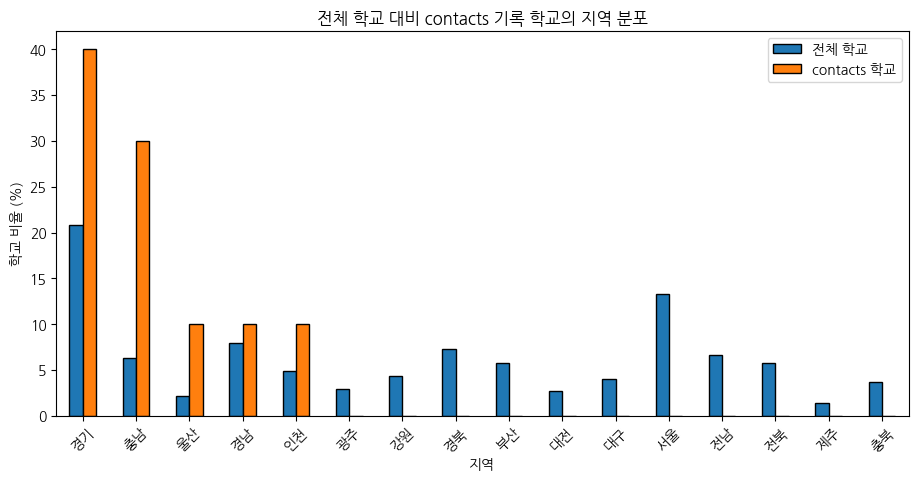

In [ ]:
# 지역별 전체 학교 비중 vs contacts 학교 비중
region_compare[
    ['all_share', 'contacts_share']
].dropna().sort_values('contacts_share', ascending=False).plot(
    kind='bar',
    figsize=(11, 5),
    edgecolor='black'
)

plt.title('전체 학교 대비 contacts 기록 학교의 지역 분포')
plt.xlabel('지역')
plt.ylabel('학교 비율 (%)')
plt.xticks(rotation=45)
plt.legend(['전체 학교', 'contacts 학교'])
plt.show()

In [ ]:
# contacts 기록이 존재하는 10개 학교 특성
network_base.loc[
    network_base['school_has_contacts'],
    [
        'school_id', 'school_address', 'region', 'school_type',
        'student_count', 'school_user_count',
        'first_signup', 'reached_40_at', 'days_to_40',
        'nearby_avg_distance'
    ]
].drop_duplicates('school_id').sort_values('first_signup')

,school_id,school_address,region,school_type,student_count,school_user_count,first_signup,reached_40_at,days_to_40,nearby_avg_distance
395,271.0,충청남도 천안시 서북구,충남,H,491.0,492,2023-04-19 09:06:00.719792,2023-04-28 03:43:18.503902,8.0,0.027831
632,369.0,충청남도 아산시,충남,H,578.0,578,2023-04-19 15:10:56.560337,2023-05-02 22:44:27.267798,13.0,0.044420
2886,5491.0,경기도 광주시,경기,H,486.0,486,2023-04-22 13:39:28.230920,2023-05-07 02:57:28.039304,14.0,0.048958
4769,352.0,충청남도 아산시,충남,H,491.0,491,2023-04-24 04:10:12.095185,2023-05-05 04:07:00.053881,10.0,0.042645
12476,4516.0,경기도 화성시,경기,H,507.0,510,2023-04-29 14:23:17.790839,2023-05-02 15:17:04.497555,3.0,0.021439
13342,4426.0,경상남도 거제시,경남,H,483.0,487,2023-04-29 16:06:03.134614,2023-05-16 00:18:41.426463,16.0,0.059672
37867,1478.0,인천광역시 서구,인천,M,489.0,488,2023-05-05 10:51:32.513375,2023-05-06 14:18:58.057918,1.0,0.029526
50452,5520.0,경기도 광명시,경기,M,500.0,500,2023-05-06 08:51:06.377706,2023-05-08 13:49:27.604223,2.0,0.015610
84886,5372.0,경기도 남양주시,경기,H,505.0,507,2023-05-07 02:33:46.412013,2023-05-10 23:47:35.094548,3.0,0.055833
118814,1719.0,울산광역시 울주군,울산,H,550.0,551,2023-05-07 14:15:09.397548,2023-05-13 08:00:50.712386,5.0,0.028149


고등학교가 8개, 중학교가 2개 존재한다

평균 가입자 수는 약 500명

40명 달성까지는 7일정도

근처 학교 거리에서는 뚜렷한 특징이 없다


## 가입 당시 학교 네트워크 규모 → 초기 재방문

In [ ]:
# 전처리된 출석 데이터 불러오기
attendance = pd.read_csv(
    path / 'accounts_attendance_clean.csv'
)

attendance.head()

,attendance_record_id,user_id,attendance_date
0,1,1446852,2023-05-27
1,1,1446852,2023-05-28
2,1,1446852,2023-05-29
3,1,1446852,2023-05-30
4,1,1446852,2023-06-03


In [ ]:
# 날짜형 변환
attendance['attendance_date'] = pd.to_datetime(attendance['attendance_date'])
network_base['created_at'] = pd.to_datetime(network_base['created_at'])
network_base['signup_date'] = network_base['created_at'].dt.normalize()

# 혹시 같은 유저-날짜가 중복되어 있으면 제거
attendance = attendance.drop_duplicates(['user_id', 'attendance_date'])

attendance[['user_id', 'attendance_date']].head()

,user_id,attendance_date
0,1446852,2023-05-27
1,1446852,2023-05-28
2,1446852,2023-05-29
3,1446852,2023-05-30
4,1446852,2023-06-03


가입 후 며칠 뒤 출석했는지 계산

In [ ]:
# 출석 기록에 가입일 연결
att_check = attendance.merge(
    network_base[['user_id', 'signup_date']].drop_duplicates('user_id'),
    on='user_id',
    how='inner'
)

# 가입일로부터 출석일까지 경과 일수
att_check['days_after_signup'] = (
    att_check['attendance_date'] - att_check['signup_date']
).dt.days

# 가입 당일은 재방문이 아니므로 이후 출석만 사용
att_check = att_check[att_check['days_after_signup'] > 0]

att_check[['user_id', 'signup_date', 'attendance_date', 'days_after_signup']].head()

,user_id,signup_date,attendance_date,days_after_signup
0,1359398,2023-05-17,2023-05-27,10
1,1359398,2023-05-17,2023-05-29,12
2,1359398,2023-05-17,2023-05-30,13
3,1359398,2023-05-17,2023-06-02,16
4,1359398,2023-05-17,2023-06-03,17


1일·3일·7일·30일 누적 재방문 여부

In [ ]:
# 기간별 누적 재방문 여부를 network_base에 추가
for day in [1, 3, 7, 30]:
    revisit_ids = att_check.loc[
        att_check['days_after_signup'] <= day,
        'user_id'
    ].unique()

    network_base[f'revisit_{day}d'] = network_base['user_id'].isin(revisit_ids)

In [ ]:
# 중요한 부분: 관측기간 보정

# 출석 데이터의 마지막 관측일
attendance_end = attendance['attendance_date'].max()

# 각 기간을 온전히 관측할 수 있었는지 여부
for day in [1, 3, 7, 30]:
    network_base[f'eligible_{day}d'] = (
        network_base['signup_date'] + pd.Timedelta(days=day) <= attendance_end
    )

In [ ]:
# 가입 당시 네트워크 규모별 재방문율

# 가입 순서 그룹별 기간별 재방문율
for day in [1, 3, 7, 30]:
    result = (
        network_base.loc[network_base[f'eligible_{day}d']]
        .groupby('join_order_group', observed=True)[f'revisit_{day}d']
        .agg(['count', 'mean'])
        .assign(revisit_rate=lambda x: (x['mean'] * 100).round(2))
        [['count', 'revisit_rate']]
    )

    display(result)

,count,revisit_rate
join_order_group,,
1~20번째,96067,0.24
21~39번째,77455,2.30
40~116번째,254264,3.49
117번째 이후,249190,3.75


,count,revisit_rate
join_order_group,,
1~20번째,96067,0.83
21~39번째,77454,4.75
40~116번째,254264,6.06
117번째 이후,249187,6.58


,count,revisit_rate
join_order_group,,
1~20번째,96064,3.41
21~39번째,77454,10.66
40~116번째,254262,12.30
117번째 이후,249158,13.64


,count,revisit_rate
join_order_group,,
1~20번째,96059,42.09
21~39번째,77446,48.06
40~116번째,254234,45.40
117번째 이후,249062,42.71


각각 가입 후 1일 / 3일 / 7일 / 30일 이내 누적 재방문율

In [ ]:
# 가입 순서 그룹별 1·3·7·30일 누적 재방문율 저장
retention_rates = {}

for day in [1, 3, 7, 30]:
    retention_rates[f'{day}일'] = (
        network_base.loc[network_base[f'eligible_{day}d']]
        .groupby('join_order_group', observed=True)[f'revisit_{day}d']
        .mean()
        .mul(100)
    )

retention_plot = pd.DataFrame(retention_rates)

retention_plot.round(2)

,1일,3일,7일,30일
join_order_group,,,,
1~20번째,0.24,0.83,3.41,42.09
21~39번째,2.30,4.75,10.66,48.06
40~116번째,3.49,6.06,12.30,45.40
117번째 이후,3.75,6.58,13.64,42.71


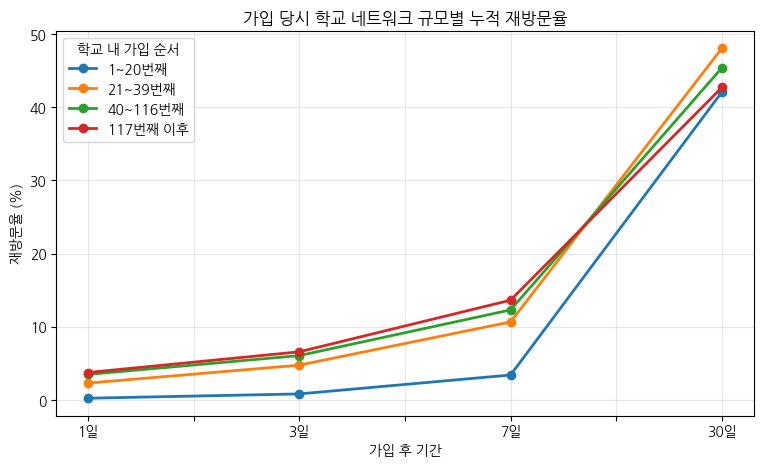

In [ ]:
# 가입 당시 학교 네트워크 규모별 재방문율 변화
ax = retention_plot.T.plot(
    marker='o',
    figsize=(9, 5),
    linewidth=2
)

plt.title('가입 당시 학교 네트워크 규모별 누적 재방문율')
plt.xlabel('가입 후 기간')
plt.ylabel('재방문율 (%)')
plt.legend(title='학교 내 가입 순서')
plt.grid(alpha=0.3)
plt.show()

## 초기 친구 연결 → 재방문

In [ ]:
# 전처리된 친구요청 데이터 불러오기
friendrequest = pd.read_csv(
    path / 'accounts_friendrequest_cleaned.csv'
)

friendrequest['created_at'] = pd.to_datetime(friendrequest['created_at'])

friendrequest.head()

,id,status,created_at,updated_at,receive_user_id,send_user_id
0,7,P,2023-04-17 18:29:11,2023-04-17 18:29:11,831962,837521
1,10,A,2023-04-17 18:29:11,2023-04-22 06:02:53,832151,837521
2,11,A,2023-04-17 18:29:11,2023-04-18 19:28:41,832340,837521
3,13,A,2023-04-17 18:29:11,2023-04-19 11:05:04,833041,837521
4,20,P,2023-04-17 18:29:11,2023-04-17 18:29:11,834415,837521


In [ ]:
# 요청을 보낸 시점이 가입 후 3일 이내인지

# 유저별 가입일 매핑용
signup_map = network_base.set_index('user_id')['signup_date']

# 친구요청을 보낸 유저의 가입일
friendrequest['send_signup_date'] = (
    friendrequest['send_user_id'].map(signup_map)
)

# 가입 후 며칠 뒤 요청했는지 계산
friendrequest['send_days'] = (
    friendrequest['created_at'].dt.normalize()
    - friendrequest['send_signup_date']
).dt.days

In [ ]:
# 친구요청을 받은 유저의 가입일
friendrequest['receive_signup_date'] = (
    friendrequest['receive_user_id'].map(signup_map)
)

# 가입 후 며칠 뒤 요청을 받았는지 계산
friendrequest['receive_days'] = (
    friendrequest['created_at'].dt.normalize()
    - friendrequest['receive_signup_date']
).dt.days

In [ ]:
# 가입 후 3일 내 친구요청 송신/수신 여부
# 가입 후 0~3일 내 요청을 보낸 유저
send_3d_ids = friendrequest.loc[
    friendrequest['send_days'].between(0, 3),
    'send_user_id'
].unique()

# 가입 후 0~3일 내 요청을 받은 유저
receive_3d_ids = friendrequest.loc[
    friendrequest['receive_days'].between(0, 3),
    'receive_user_id'
].unique()

# 유저 단위 지표 추가
network_base['sent_friend_3d'] = network_base['user_id'].isin(send_3d_ids)
network_base['received_friend_3d'] = network_base['user_id'].isin(receive_3d_ids)

# 둘 중 하나라도 있으면 초기 친구 연결 경험
network_base['friend_interaction_3d'] = (
    network_base['sent_friend_3d'] |
    network_base['received_friend_3d']
)

In [ ]:
# 초기 친구 연결 여부별 재방문율

# 초기 친구 상호작용 여부에 따른 재방문율
(
    network_base.groupby('friend_interaction_3d')
    [['revisit_1d', 'revisit_3d', 'revisit_7d', 'revisit_30d']]
    .mean()
    .mul(100)
    .round(2)
)

,revisit_1d,revisit_3d,revisit_7d,revisit_30d
friend_interaction_3d,,,,
False,0.18,0.30,0.72,21.16
True,3.04,5.45,11.54,44.66


In [ ]:
# 초기 친구 상호작용 여부별 누적 재방문율 + 시각화

# 기간별로 충분히 관측 가능한 유저만 사용해 재방문율 계산
friend_revisit = pd.DataFrame()

for day in [1, 3, 7, 30]:
    rate = (
        network_base.loc[network_base[f'eligible_{day}d']]
        .groupby('friend_interaction_3d')[f'revisit_{day}d']
        .mean()
        .mul(100)
    )
    friend_revisit[f'{day}일'] = rate

friend_revisit.round(2)

,1일,3일,7일,30일
friend_interaction_3d,,,,
False,0.18,0.29,0.71,21.27
True,3.04,5.45,11.54,44.66


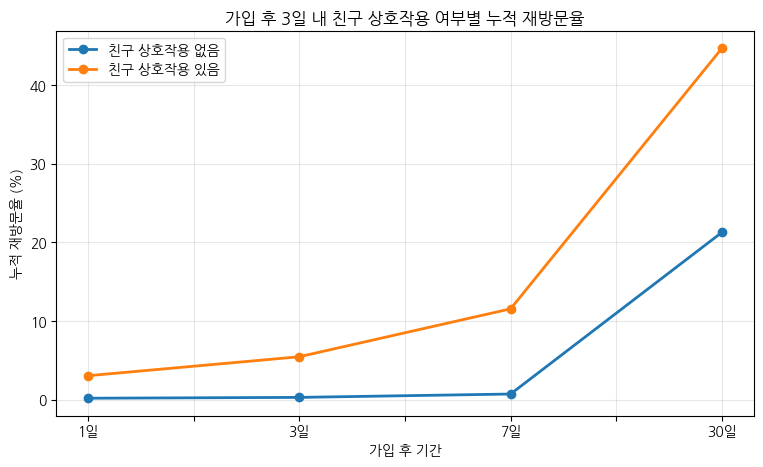

In [ ]:
# 초기 친구 상호작용 유무별 누적 재방문율 시각화
ax = friend_revisit.T.plot(
    marker='o',
    figsize=(9, 5),
    linewidth=2
)

plt.title('가입 후 3일 내 친구 상호작용 여부별 누적 재방문율')
plt.xlabel('가입 후 기간')
plt.ylabel('누적 재방문율 (%)')
plt.legend(['친구 상호작용 없음', '친구 상호작용 있음'])
plt.grid(alpha=0.3)
plt.show()

## 친구요청 유형 구분 [없음 / 보내기만 / 받기만 / 둘 다]

In [ ]:
# 가입 후 3일 내 친구요청 유형 구분
network_base['friend_3d_type'] = '없음'

network_base.loc[
    network_base['sent_friend_3d'] & ~network_base['received_friend_3d'],
    'friend_3d_type'
] = '보내기만'

network_base.loc[
    ~network_base['sent_friend_3d'] & network_base['received_friend_3d'],
    'friend_3d_type'
] = '받기만'

network_base.loc[
    network_base['sent_friend_3d'] & network_base['received_friend_3d'],
    'friend_3d_type'
] = '송수신 모두'

In [ ]:
network_base['friend_3d_type'].value_counts()

,count
friend_3d_type,
송수신 모두,599377
받기만,33626
보내기만,31776
없음,12201


In [ ]:
# 충분히 7일 관측 가능한 유저만 비교
friend_type_7d = (
    network_base.loc[network_base['eligible_7d']]
    .groupby('friend_3d_type')['revisit_7d']
    .agg(['count', 'mean'])
)

friend_type_7d['revisit_rate'] = (
    friend_type_7d['mean'] * 100
).round(2)

friend_type_7d

,count,mean,revisit_rate
friend_3d_type,,,
받기만,33625,0.023257,2.33
보내기만,31751,0.170357,17.04
송수신 모두,599371,0.117648,11.76
없음,12191,0.007136,0.71


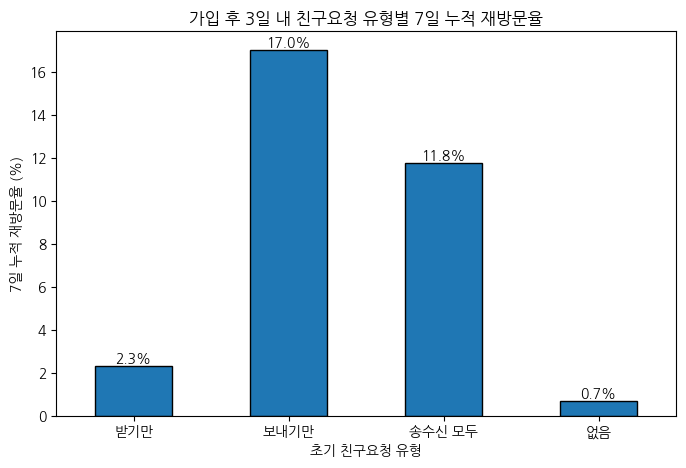

In [ ]:
# 친구요청 유형별 7일 누적 재방문율
ax = friend_type_7d['revisit_rate'].plot(
    kind='bar',
    figsize=(8, 5),
    edgecolor='black'
)

for i, v in enumerate(friend_type_7d['revisit_rate']):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')

plt.title('가입 후 3일 내 친구요청 유형별 7일 누적 재방문율')
plt.xlabel('초기 친구요청 유형')
plt.ylabel('7일 누적 재방문율 (%)')
plt.xticks(rotation=0)
plt.show()